In [1]:
import matplotlib.pyplot as plt
import numpy as np
from astropy.io import fits
import bokeh.plotting as bok
import os
from numpy.polynomial.polynomial import Polynomial
import pandas as pd
from PyAstronomy import pyasl
from scipy.signal import correlate
from astropy.stats import sigma_clip
from scipy.interpolate import interp1d
from astroscrappy import detect_cosmics
import ast
from scipy.stats import chisquare
import scipy
import scipy.integrate
import scipy.stats
from multiprocessing import Pool
from functools import partial

%matplotlib inline


### Checking for regions to apply masks

In [2]:
def get_synth(star, el, abunds, savepath, plotname, masks=False):
    
    # Getting the list of synthetic spectra
    # path = f'/data/misfit/benlowe/xshooter/p113/korg_data/upper_limits_v6/{star}/{el}/synth_specs/'
    path = f'/data/misfit/benlowe/xshooter/p115/korg_data/upper_limits_v2/{star}/{el}/synth_specs/'

    
    specs = [path + f for f in os.listdir(path) if f.endswith('.csv') and not f.startswith(el)]
    specs.sort()
    # abunds = np.arange(1, -4.01, -0.01)
    
    # Loading in the chisquare values
    # chi_path = f'/data/misfit/benlowe/xshooter/p113/korg_data/upper_limits_v6/{star}/{el}/chisqrs.csv'
    chi_path = f'/data/misfit/benlowe/xshooter/p115/korg_data/upper_limits_v2/{star}/{el}/chisqrs.csv'
    chi_df = pd.read_csv(chi_path)
    
    # Taking the minimum chisq value and the corresponding abundance
    min_chi = chi_df['chisq_obs'].min()
    min_abund = chi_df.loc[chi_df['chisq_obs'] == min_chi, 'xfe'].values[0]

    # Loading in the observed spectra (all the same, so will take the first entry)
    obs_df = pd.read_csv(specs[0])
    obs_flux = obs_df['obs_flux'].to_numpy()
    obs_flux_err = obs_df['obs_flux_err'].to_numpy()
    obs_wave = obs_df['obs_wave'].to_numpy()
    
    if el == 'C_I':
        c_reg = np.where((obs_wave >= 4285) & (obs_wave <= 4317))
        obs_flux = obs_flux[c_reg]
        obs_flux_err = obs_flux_err[c_reg]
        obs_wave = obs_wave[c_reg]

    # Loading in the empty spectra
    # empty_path = f'/data/misfit/benlowe/xshooter/p113/korg_data/upper_limits_v6/{star}/{el}/empty_specs/'
    empty_path = f'/data/misfit/benlowe/xshooter/p115/korg_data/upper_limits_v2/{star}/{el}/empty_specs/'

    empty_specs = [empty_path + f for f in os.listdir(empty_path) if f.endswith('.csv') and not f.startswith(el)]
    empty_df = pd.read_csv(empty_specs[0])
    empty_flux = empty_df['empty_flux'].to_numpy()
    empty_wave = empty_df['empty_wave'].to_numpy()
    
    if el == 'C_I':
        c_reg = np.where((empty_wave >= 4285) & (empty_wave <= 4317))
        empty_flux = empty_flux[c_reg]
        empty_wave = empty_wave[c_reg]

    # Loading in the synthetic spectra
    synth_all = []
    synth_min = []
    for f in specs:
        
        # Getting the synthetic specra for our desired abudnances
        try:
            synth_abund = float((f.split('/')[-1]).split('_')[0])
        except ValueError:
            continue
        if synth_abund in abunds:
            synth_df = pd.read_csv(f)
            synth_flux = synth_df['synth_flux'].to_numpy()
            synth_wave = synth_df['synth_wave'].to_numpy()
            
            if el == 'C_I':
                c_reg = np.where((synth_wave >= 4285) & (synth_wave <= 4317))
                synth_flux = synth_flux[c_reg]
                synth_wave = synth_wave[c_reg]
            
            synth_dict = {'abund': synth_abund, 'wave': synth_wave, 'flux': synth_flux}
            synth_all.append(synth_dict)
            
        # # Getting the synthetic spectra for the minimum abundance
        # if synth_abund == -0.74:
        #     synth_df = pd.read_csv(f)
        #     synth_flux = synth_df['synth_flux'].values
        #     synth_wave = synth_df['synth_wave'].values
            
        #     synth_dict = {'abund': min_abund, 'wave': synth_wave, 'flux': synth_flux}
        #     synth_min.append(synth_dict)
            
    synth_all_df = pd.DataFrame(synth_all)
    # synth_min_df = pd.DataFrame(synth_min)
    synth_all_df = synth_all_df.sort_values(by='abund')

    # synth_df = pd.read_csv(f'/data/misfit/benlowe/xshooter/p113/korg_data/upper_limits_v6/{star}/{el}/synth_specs/{min_abund}_spec.csv')
    # synth_all_df = pd.DataFrame({'abund': [min_abund], 'wave': [synth_df['synth_wave'].values], 'flux': [synth_df['synth_flux'].values]})

    # display(synth_all_df)
    
    # Plotting
    plt.figure(figsize=(10,6))

    # Plotting the observed dataset
    plt.plot(obs_wave, obs_flux, color='black', label='Observed', linewidth=1.5)
    plt.errorbar(obs_wave, obs_flux, yerr=obs_flux_err, fmt='o', color='grey', alpha=0.5, markersize=2)

    # Plotting the empty dataset
    plt.plot(empty_wave, empty_flux, color='black', label='Empty', linestyle='--', linewidth=1.5)

    # Plotting the synthetic dataset
    # print(star)
    for i in range(len(synth_all_df)):
        print(synth_all_df['abund'][i])
        plt.plot(synth_all_df['wave'][i], synth_all_df['flux'][i], alpha=1, linewidth=0.4) # label=f"[N/Fe] = {synth_all_df['abund'][i]}"
        
    # plt.plot(synth_min_df['wave'][0], synth_min_df['flux'][0], label=f"[N/Fe] = -0.74", linewidth=1.5)
        
    # masks = [(3359, 3360.5)]
    ymin, ymax = plt.gca().get_ylim()
    if masks:
        for start, end in masks:
            fill_range = (obs_wave >= start) & (obs_wave <= end)
            plt.fill_between(obs_wave[fill_range], y1=ymin, y2=ymax, color="grey", alpha=0.5)
    # for start, end in masks:
    #     fill_range = (obs_wave >= start) & (obs_wave <= end)
    #     plt.fill_between(obs_wave[fill_range], y1=0, y2=1.05, color="grey", alpha=0.5)

    plt.legend(fancybox=False)
    plt.xlabel('Wavelength (Å)')
    plt.ylabel('Normalised Flux')
    # plt.ylim(0, 1.05)
    plt.title(f'{star}')
    plt.tight_layout()

    plt.savefig(f'{savepath}{star}_{plotname}', dpi=300, bbox_inches='tight')

#### For NH

-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0


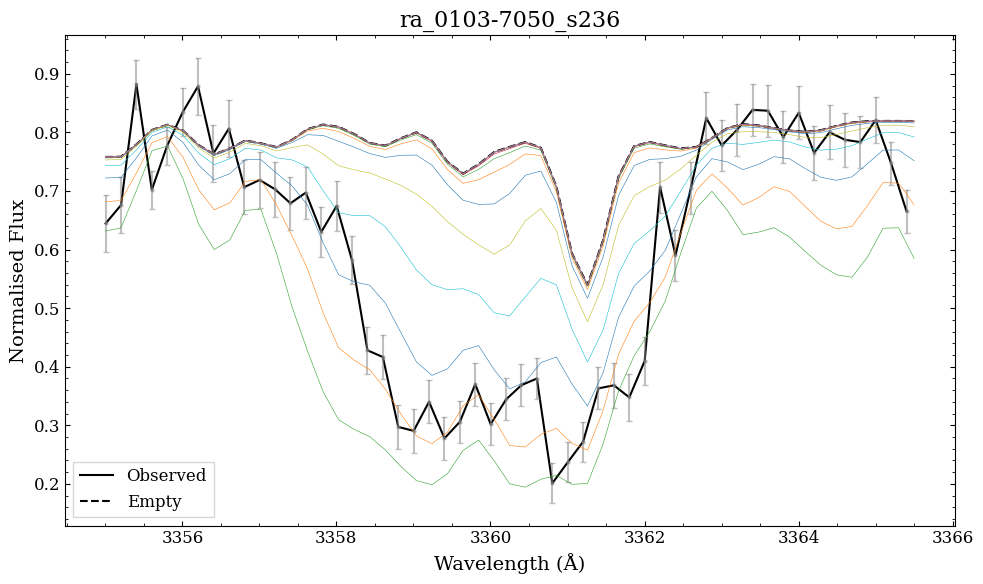

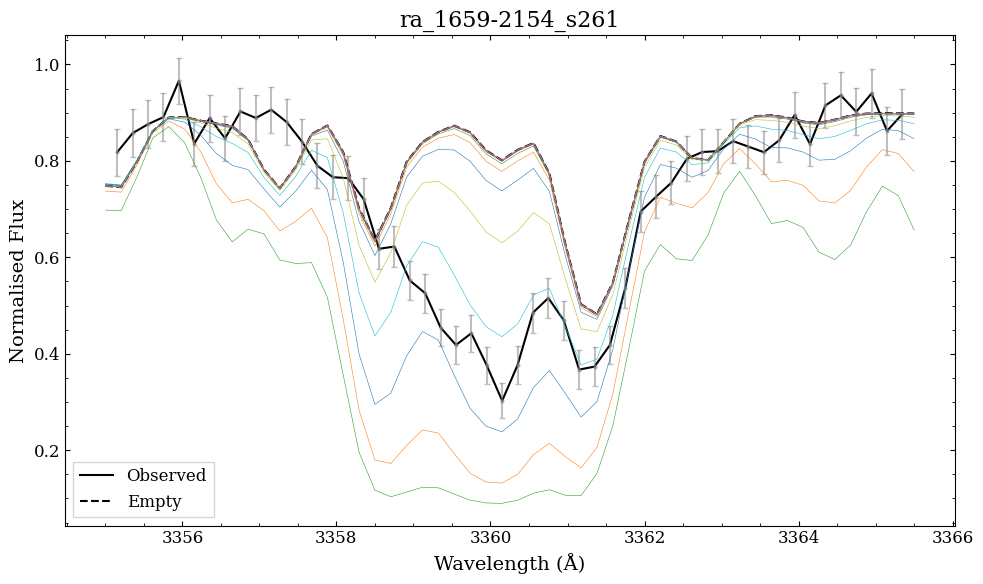

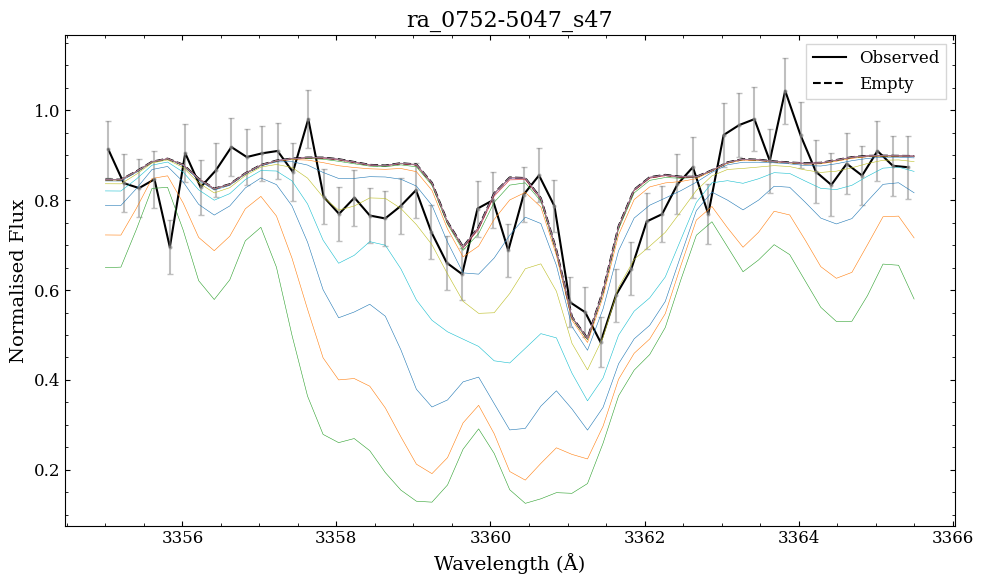

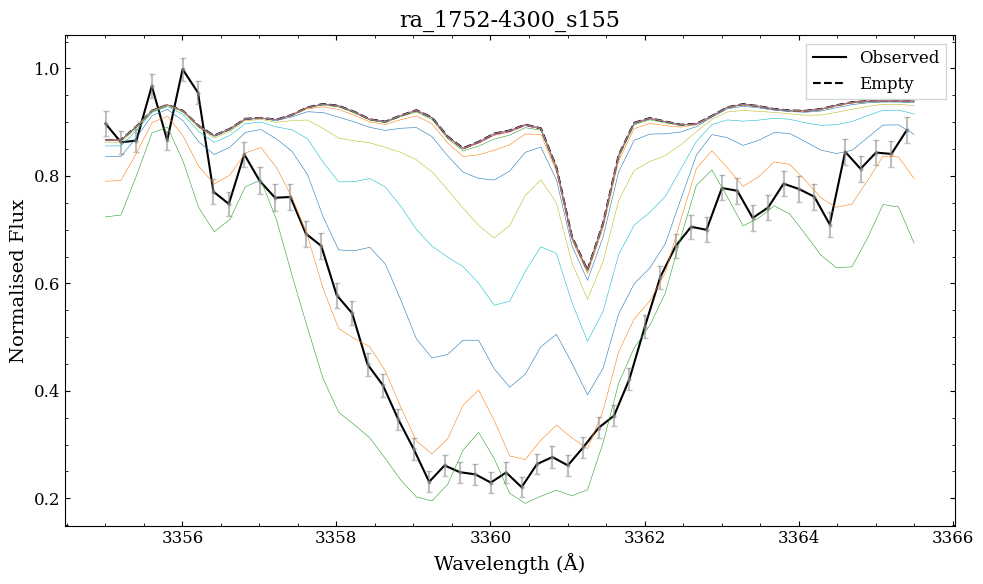

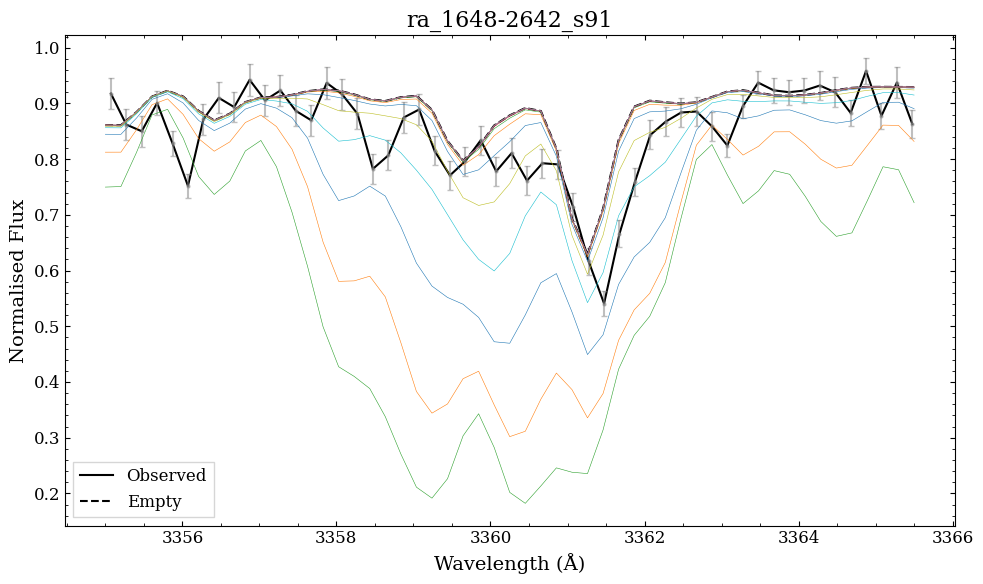

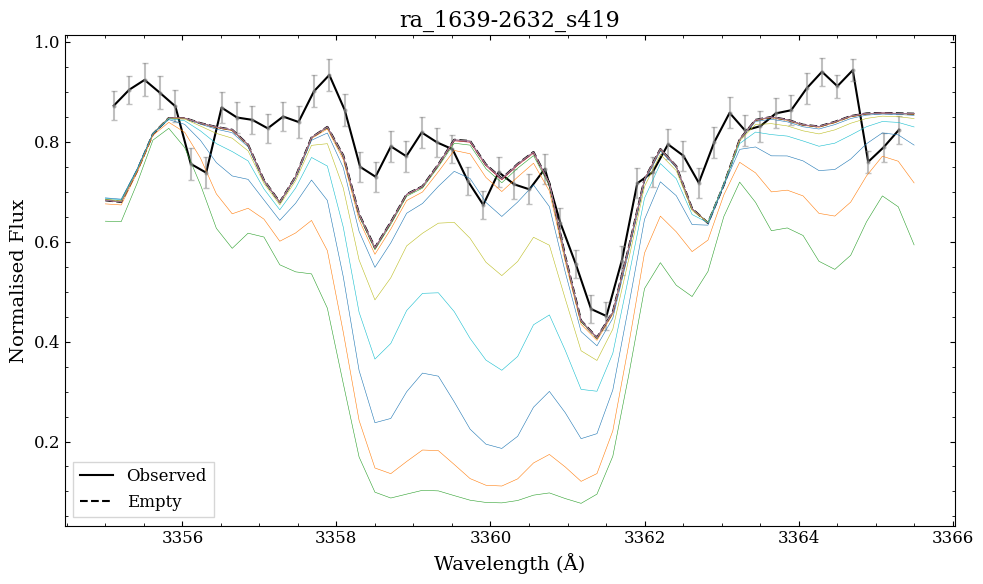

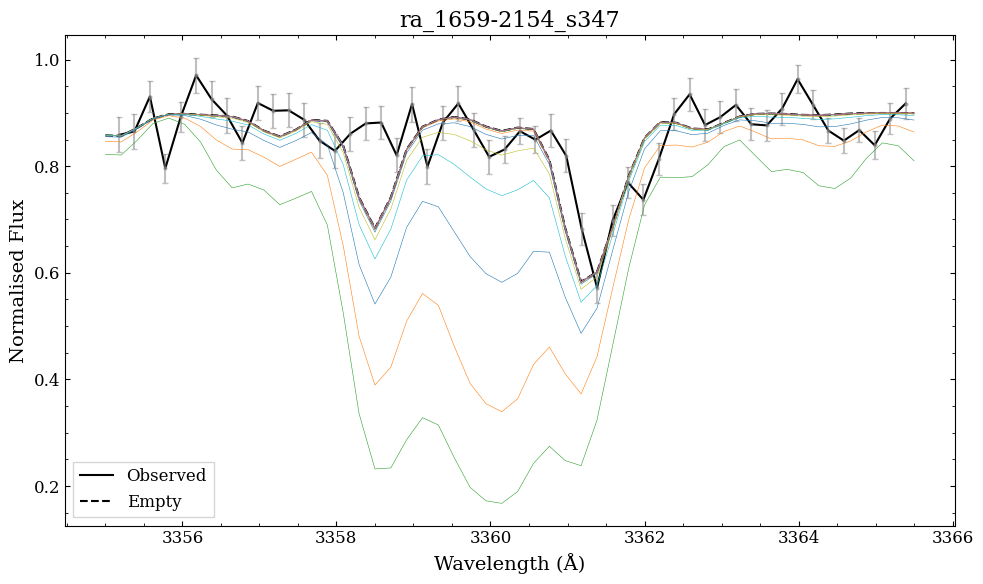

In [3]:
# N_stars = ["ra_0103-7050_s236", "ra_0752-5047_s47", "ra_1648-2642_s91", 
#            "ra_1659-2154_s261", "ra_1659-2154_s347", "ra_1752-4300_s155"]
# N_stars = ['ra_1658-2454_s22']
N_stars = [s for s in os.listdir('/data/misfit/benlowe/xshooter/p115/korg_data/abunds_v2/final_iter9/') if s.startswith('ra_')] # '/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter9/'
# savepath = '/data/misfit/benlowe/xshooter/p113/results/ch_nh_fits_new_v2/nh_firstlook/'
savepath = '/data/misfit/benlowe/xshooter/p115/korg_data/ch_nh_fits/v3/'
plot_name = 'nh_firstlook.png'

# Running for abundances from +2 to -4 in 0.5dex steps
abunds = [round(x, 2) for x in np.arange(2, -4.01, -0.5)]
for star in N_stars:
    get_synth(star, "N_I", abunds, savepath, plot_name)

-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0


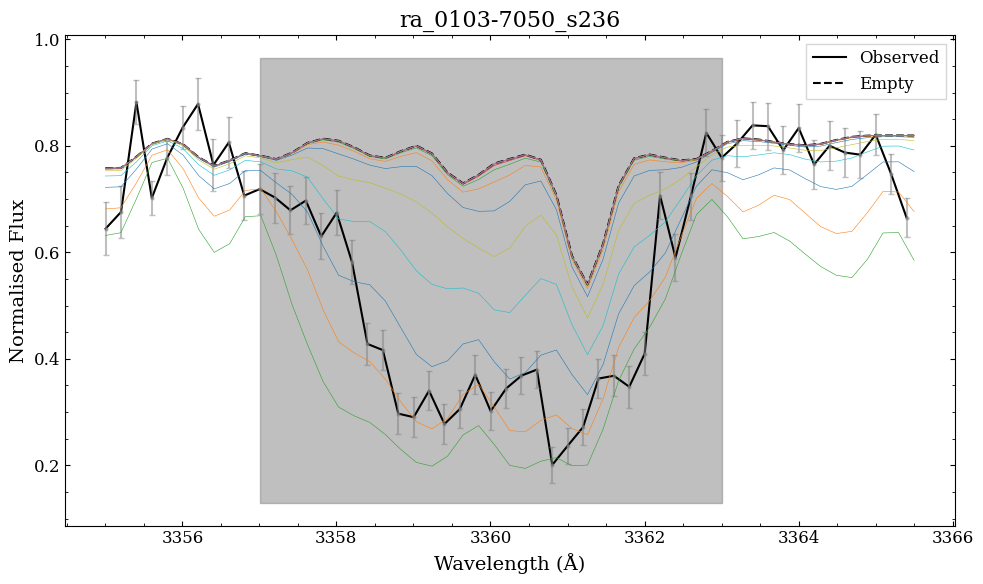

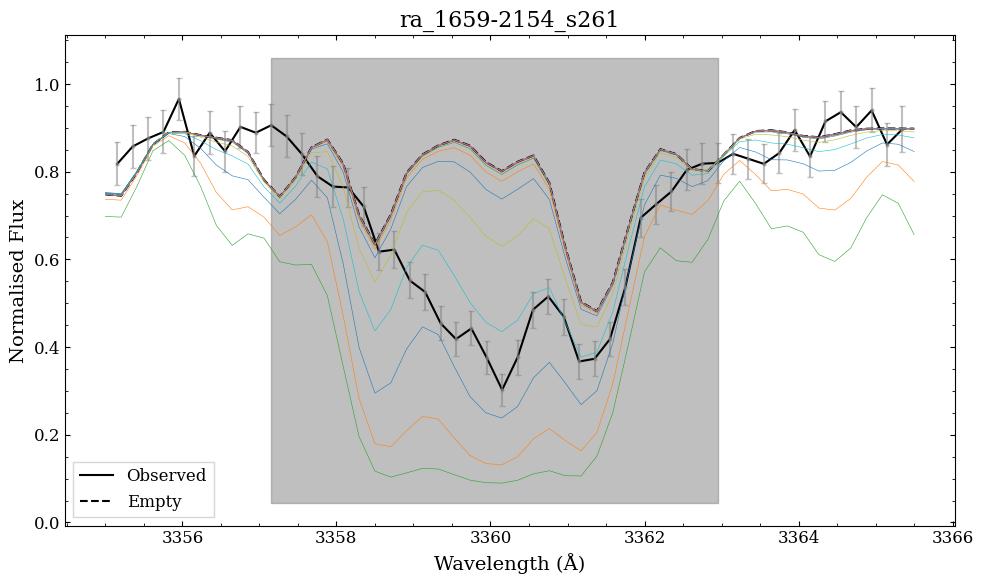

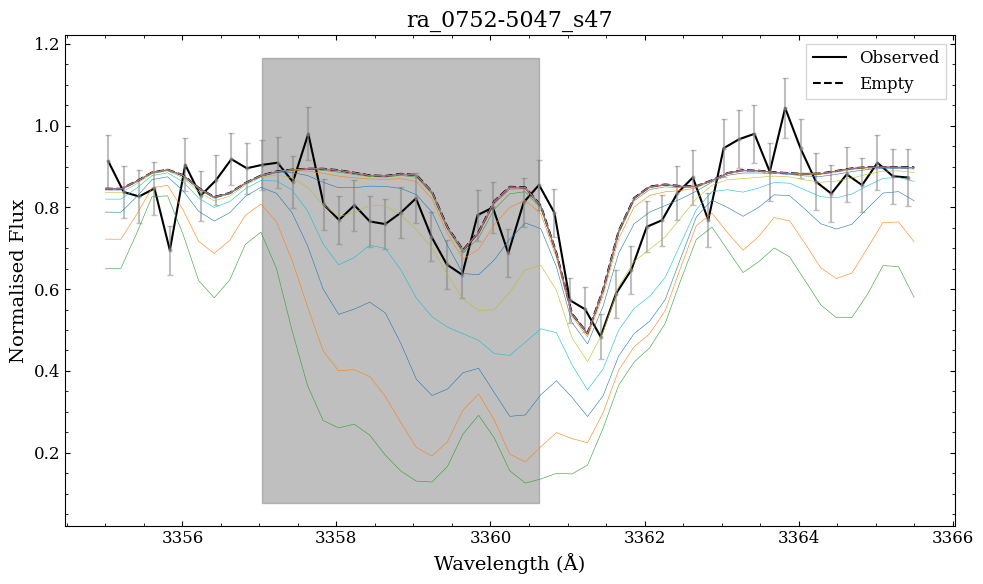

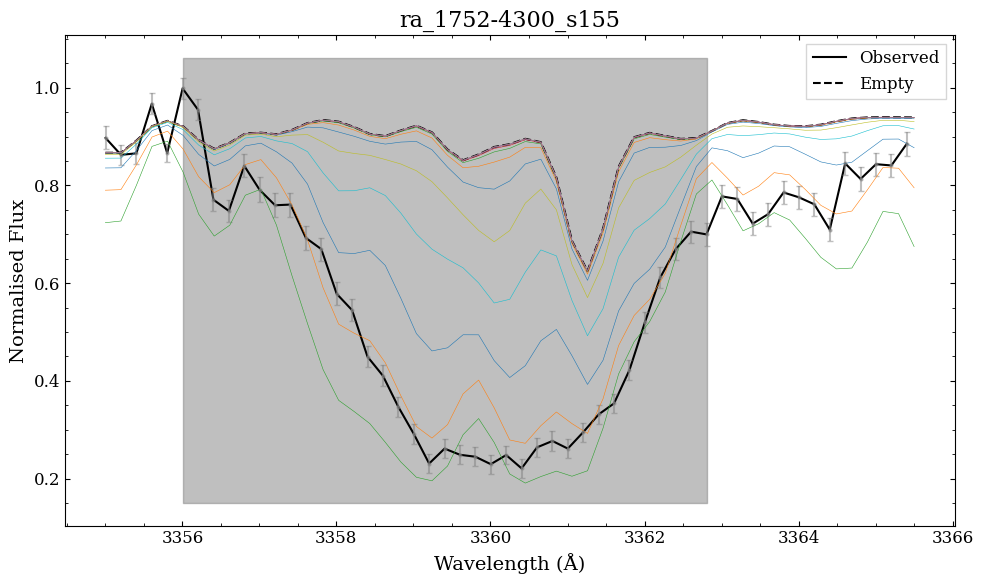

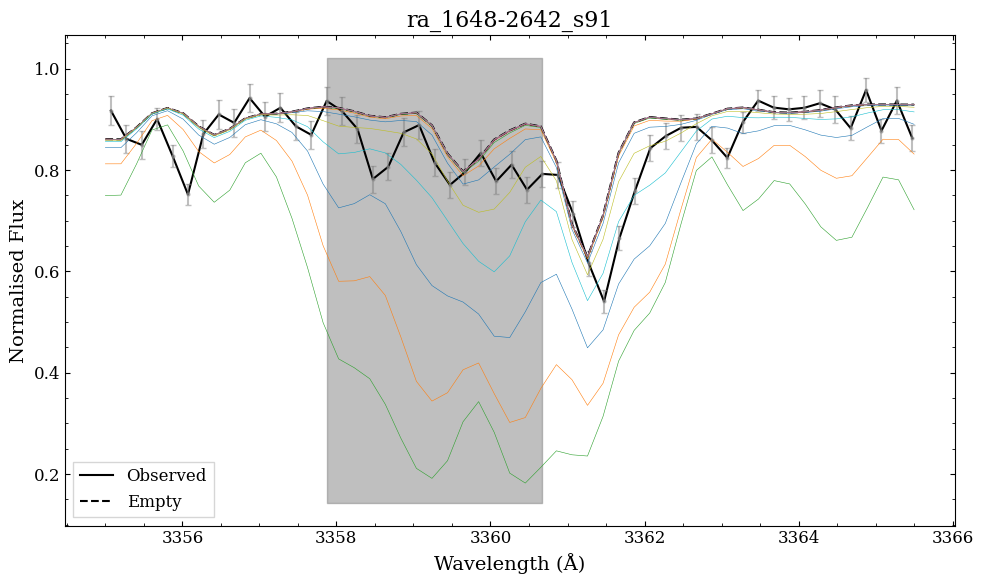

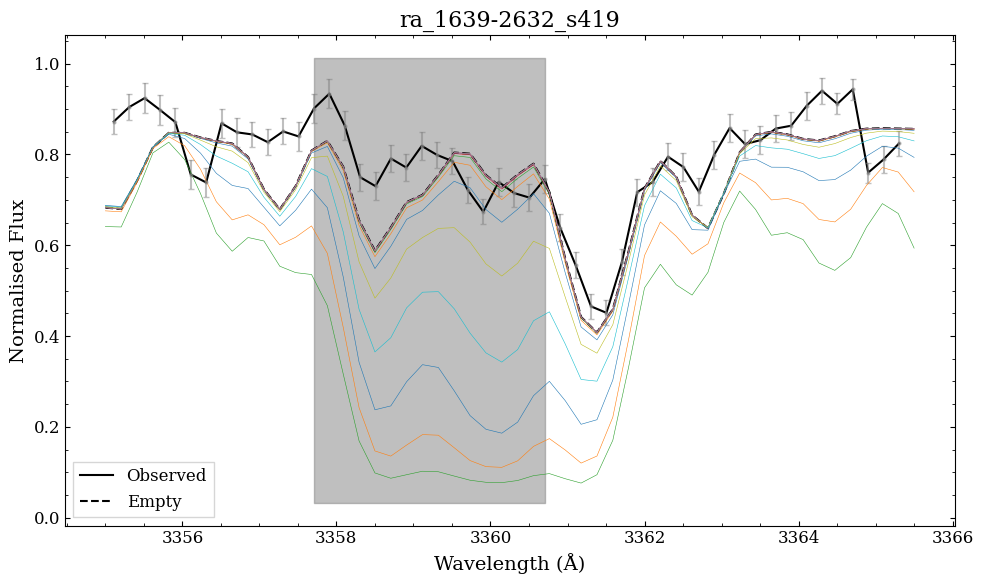

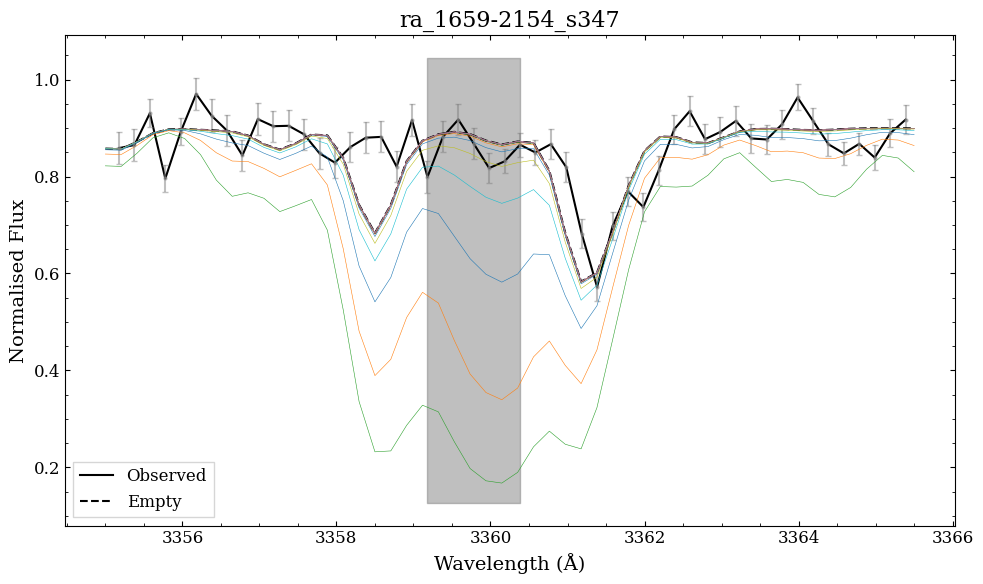

In [4]:
# N_stars = ['ra_0103-7050_s163', 'ra_0834-5220_s316', 'ra_1604-2712_s292', 'ra_1624-2150_s278', 
#            'ra_1633-2814_s284', 'ra_1648-0653_s38', 'ra_1658-2454_s22', 'ra_1659-2154_s114']
# N_stars = ['ra_1658-2454_s22']
# N_stars = [s for s in os.listdir('/data/misfit/benlowe/xshooter/p115/korg_data/abunds/final/') if s.startswith('ra_')] # /data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter9/
# savepath = '/data/misfit/benlowe/xshooter/p113/results/ch_nh_fits_new_v2/nh_firstlook/'
savepath = '/data/misfit/benlowe/xshooter/p115/korg_data/ch_nh_fits/v3/'
plot_name = 'nh_firstlook_mask.png'


# Loading in the masks
masks_df = pd.read_csv('/data/misfit/benlowe/xshooter/p115/korg_data/nh_masks.csv')

# Running first iteration - with 0.5dex steps
abunds = [round(x, 2) for x in np.arange(2, -4.01, -0.5)]
for star in N_stars:
    
    # Extracting the mask for the star
    star_maskmin = masks_df.loc[masks_df['star_id'] == star, 'nh_maskmin'].values[0]
    star_maskmax = masks_df.loc[masks_df['star_id'] == star, 'nh_maskmax'].values[0]
    star_mask = [(star_maskmin, star_maskmax)]

    get_synth(star, "N_I", abunds, savepath, plot_name, star_mask)

#### For CH

-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0


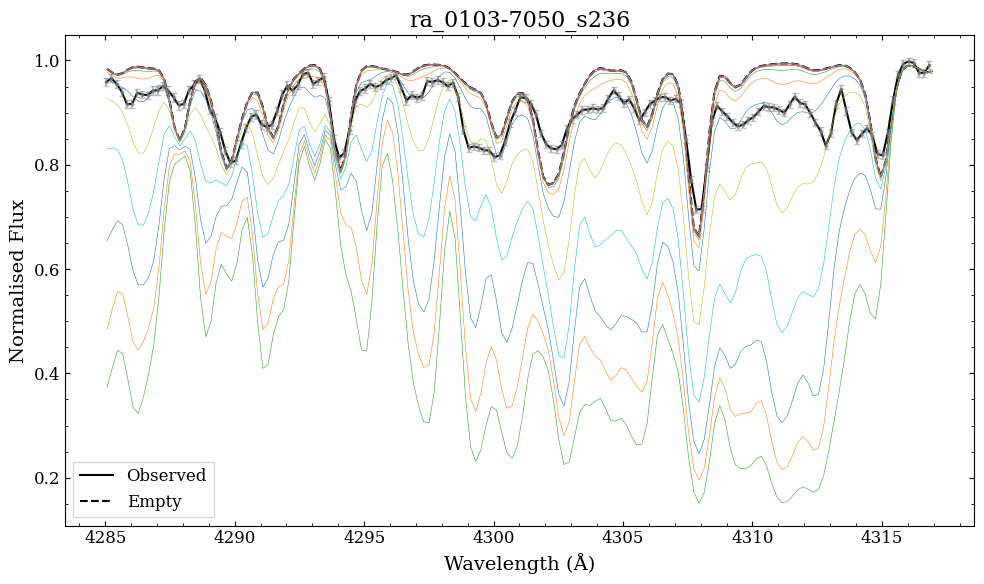

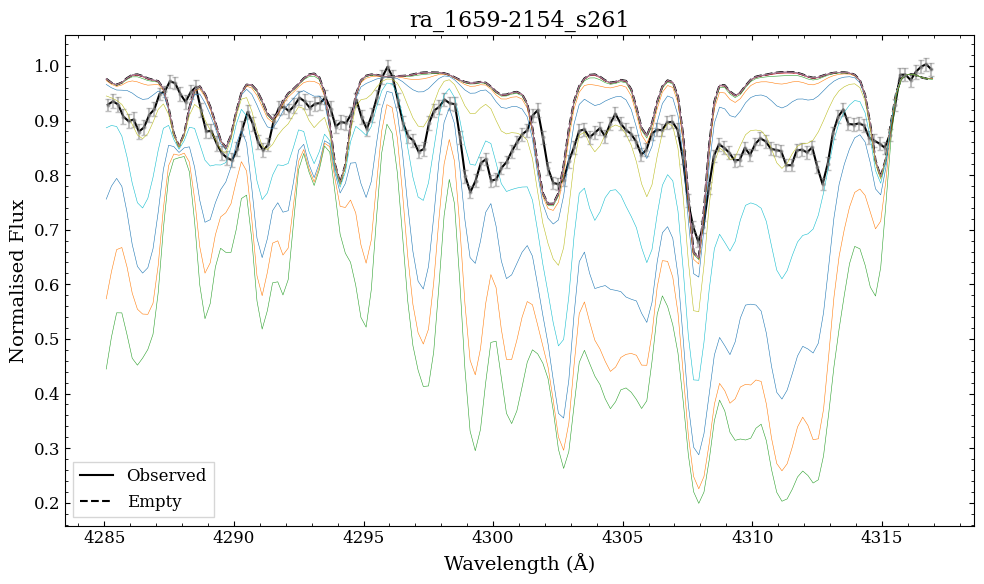

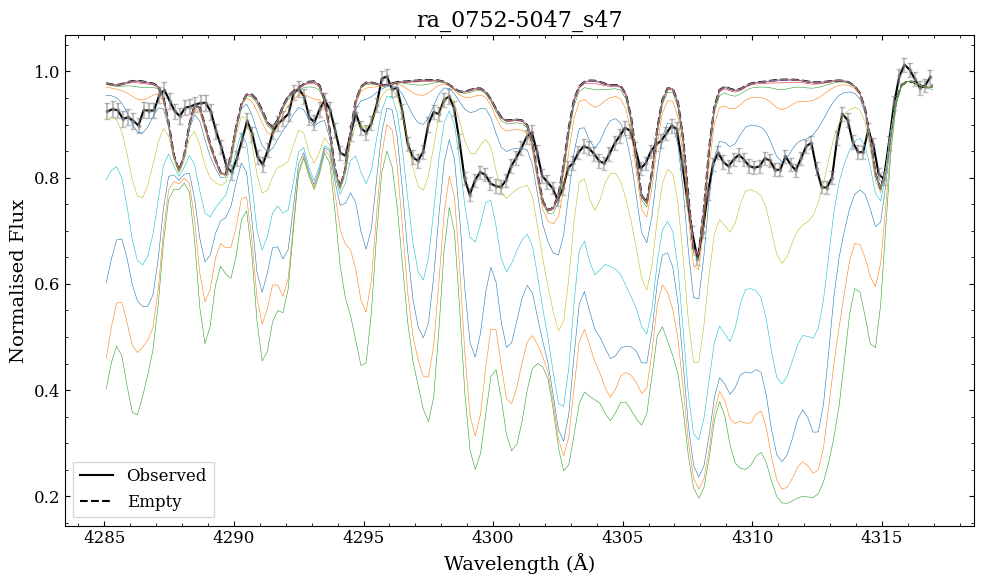

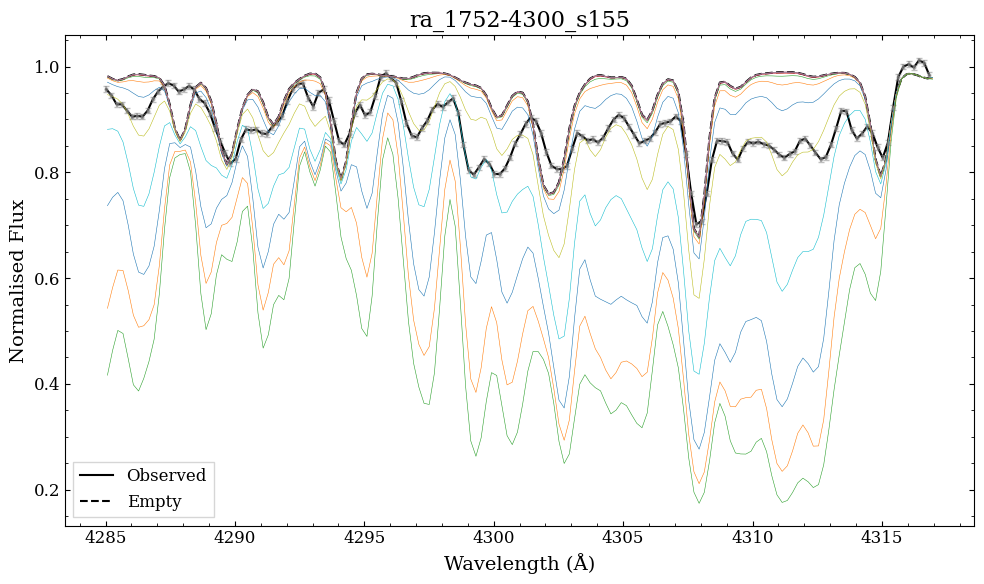

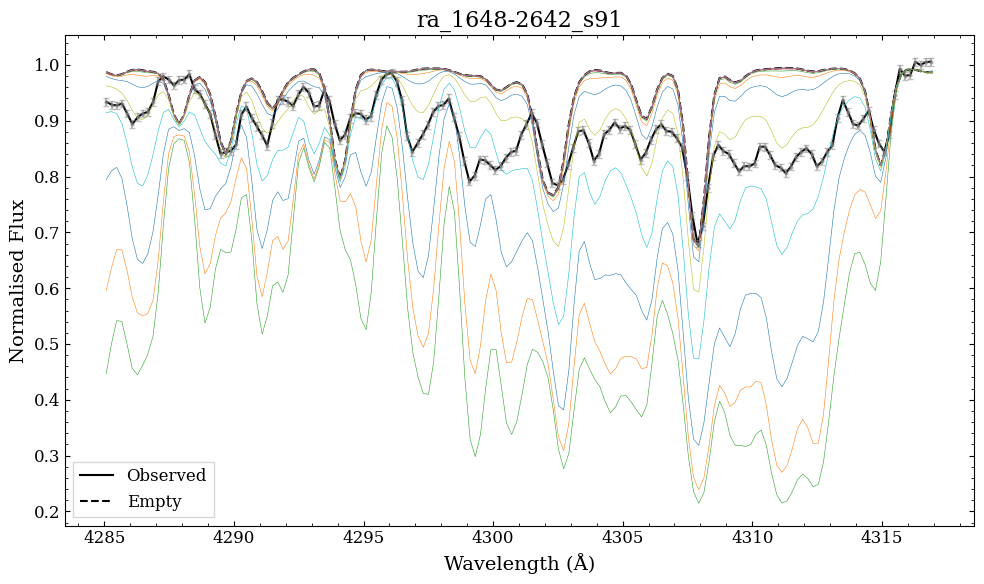

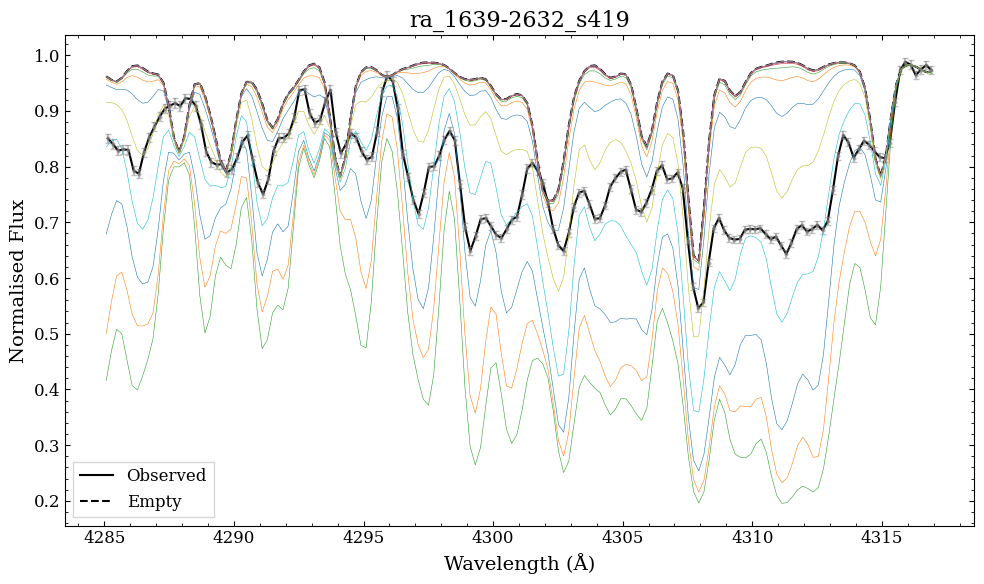

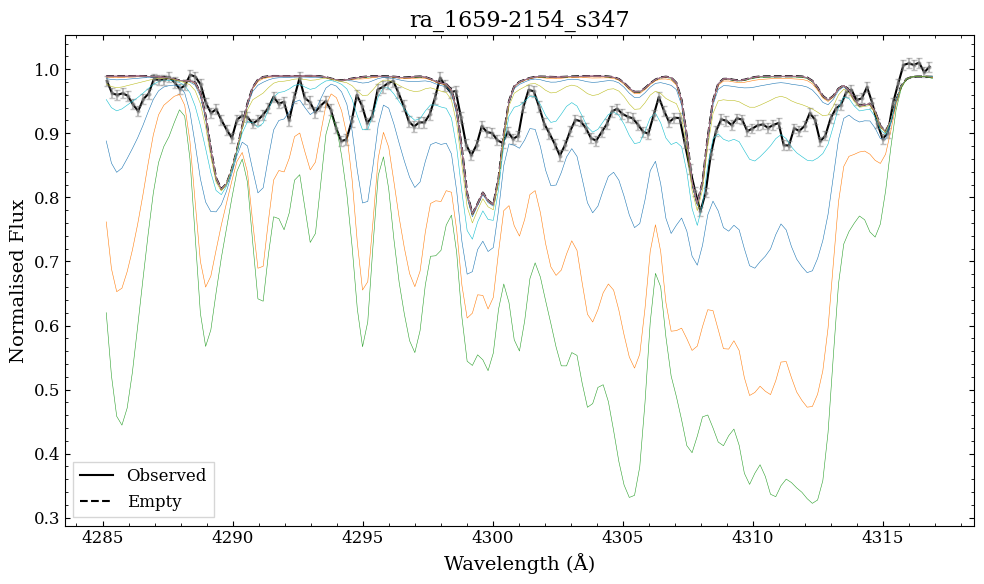

In [5]:
# N_stars = ["ra_0103-7050_s236", "ra_0752-5047_s47", "ra_1648-2642_s91", 
#            "ra_1659-2154_s261", "ra_1659-2154_s347", "ra_1752-4300_s155"]
# N_stars = ['ra_1658-2454_s22']
# N_stars = [s for s in os.listdir('/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter9/') if s.startswith('ra_')]
N_stars = [s for s in os.listdir('/data/misfit/benlowe/xshooter/p115/korg_data/abunds_v2/final_iter9/') if s.startswith('ra_')]

# savepath = '/data/misfit/benlowe/xshooter/p113/results/ch_nh_fits_new_v2/ch_firstlook/'
savepath = '/data/misfit/benlowe/xshooter/p115/korg_data/ch_nh_fits/v3/'
plot_name = 'ch_firstlook.png'

# Running first iteration - with 0.5dex steps
abunds = [round(x, 2) for x in np.arange(2, -4.01, -0.5)]
for star in N_stars:
    get_synth(star, "C_I", abunds, savepath, plot_name)

-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0
-0.5
-1.0
-1.5
-2.0
-2.5
-3.0
-3.5
-4.0
0.0
0.5
1.0
1.5
2.0


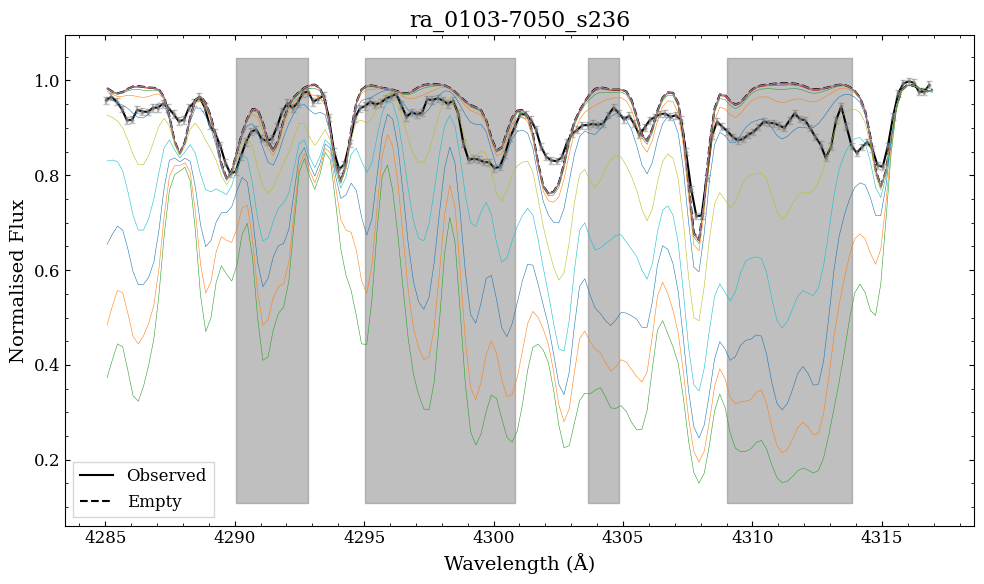

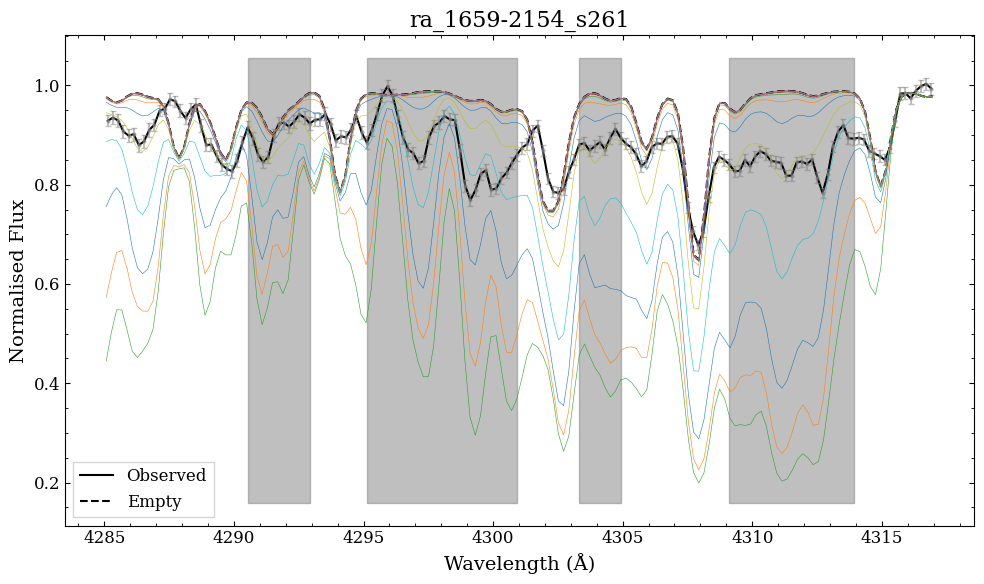

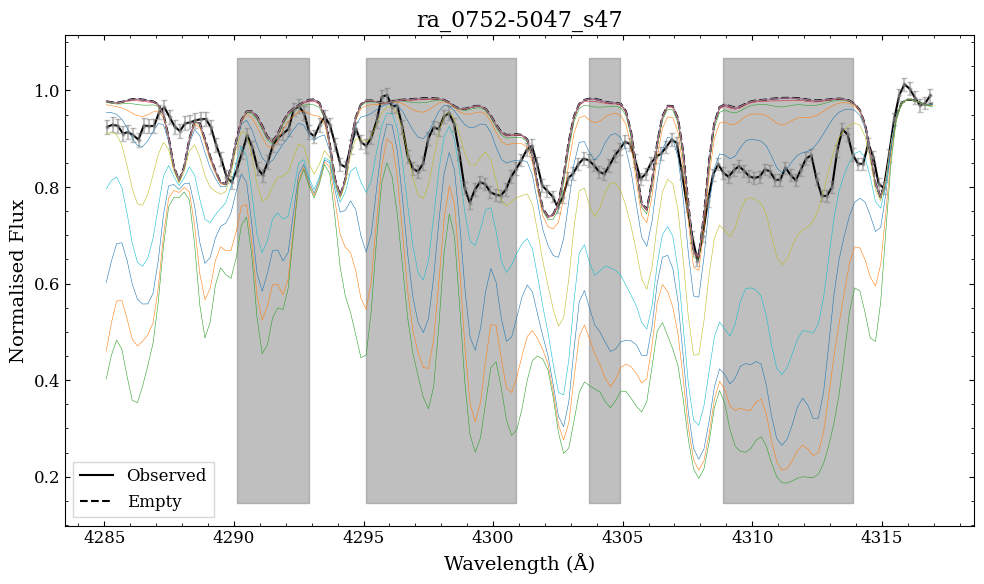

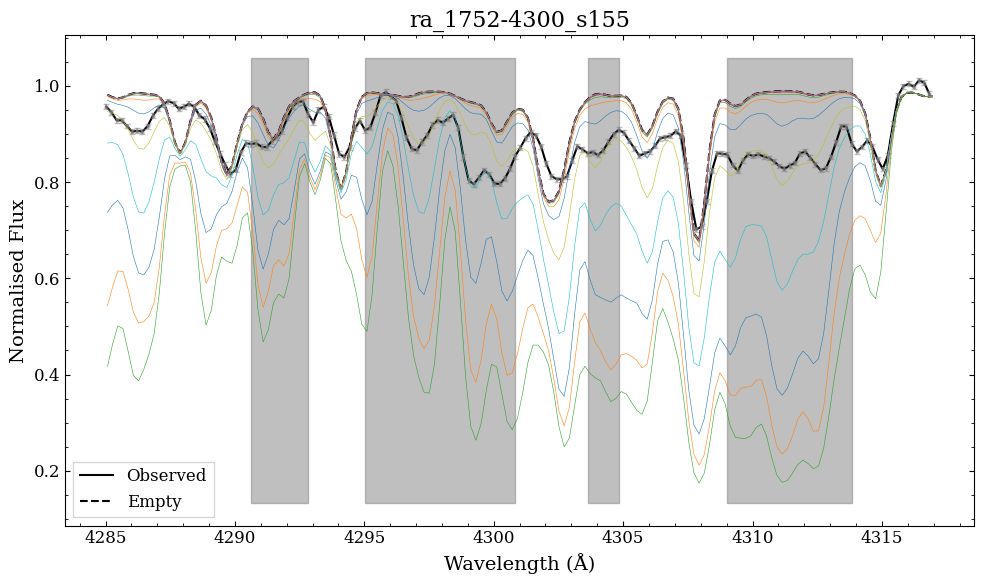

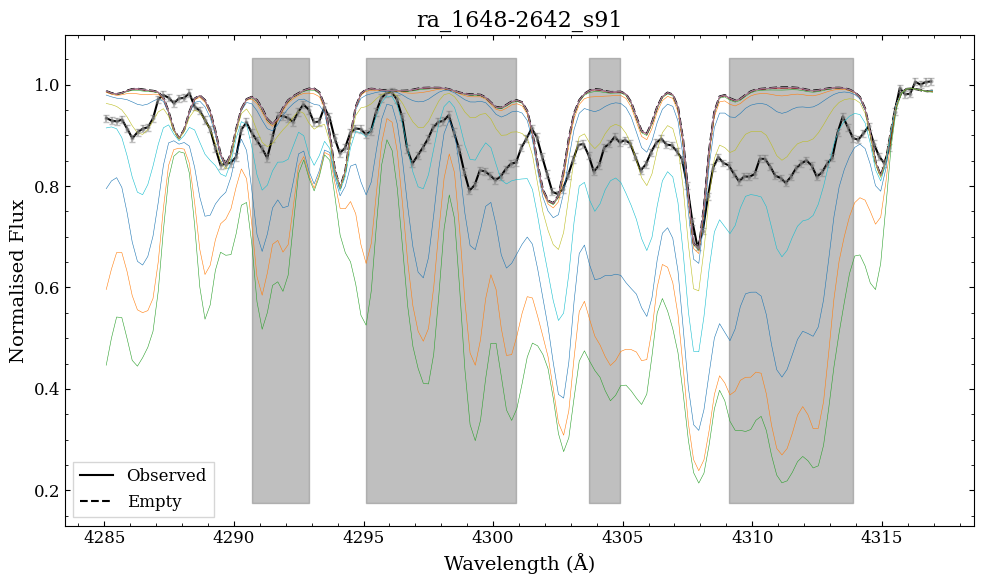

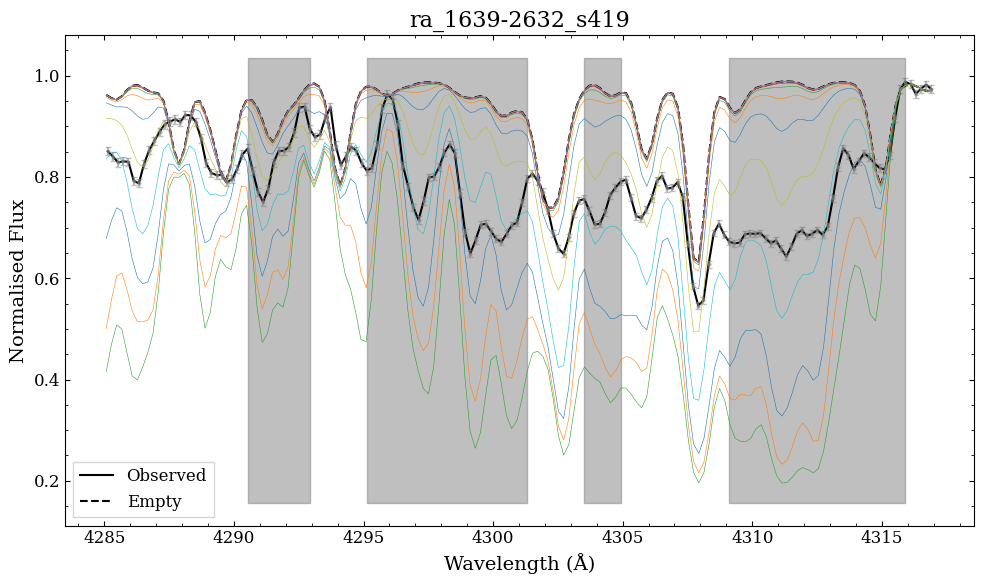

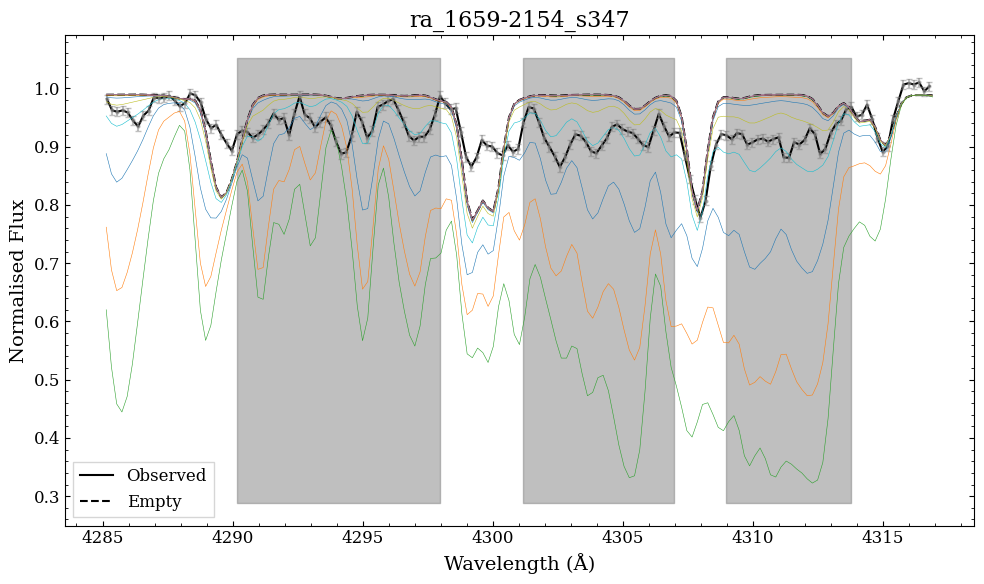

In [6]:
# N_stars = ['ra_0103-7050_s163', 'ra_0834-5220_s316', 'ra_1604-2712_s292', 'ra_1624-2150_s278', 
#            'ra_1633-2814_s284', 'ra_1648-0653_s38', 'ra_1658-2454_s22', 'ra_1659-2154_s114']
# N_stars = ['ra_1658-2454_s22']
# N_stars = [s for s in os.listdir('/data/misfit/benlowe/xshooter/p115/korg_data/abunds/final/') if s.startswith('ra_')] #'/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter9/'
# savepath = '/data/misfit/benlowe/xshooter/p113/results/ch_nh_fits_new_v2/ch_firstlook/'
savepath = '/data/misfit/benlowe/xshooter/p115/korg_data/ch_nh_fits/v3/'
plot_name = 'ch_firstlook_mask.png'

# Loading in the masks
masks_df = pd.read_csv('/data/misfit/benlowe/xshooter/p115/korg_data/ch_masks.csv') # '/data/misfit/benlowe/xshooter/p113/korg_data/ch_masks.csv'

# Running first iteration - with 0.5dex steps
abunds = [round(x, 2) for x in np.arange(2, -4.01, -0.5)]
for star in N_stars:
    
    # Extracting the mask for the star
    star_maskmin1 = masks_df.loc[masks_df['star_id'] == star, 'ch_maskmin1'].values[0]
    star_maskmax1 = masks_df.loc[masks_df['star_id'] == star, 'ch_maskmax1'].values[0]
    star_maskmin2 = masks_df.loc[masks_df['star_id'] == star, 'ch_maskmin2'].values[0]
    star_maskmax2 = masks_df.loc[masks_df['star_id'] == star, 'ch_maskmax2'].values[0]
    star_maskmin3 = masks_df.loc[masks_df['star_id'] == star, 'ch_maskmin3'].values[0]
    star_maskmax3 = masks_df.loc[masks_df['star_id'] == star, 'ch_maskmax3'].values[0]
    star_maskmin4 = masks_df.loc[masks_df['star_id'] == star, 'ch_maskmin4'].values[0]
    star_maskmax4 = masks_df.loc[masks_df['star_id'] == star, 'ch_maskmax4'].values[0]
    star_mask = [(star_maskmin1, star_maskmax1), (star_maskmin2, star_maskmax2), (star_maskmin3, star_maskmax3), (star_maskmin4, star_maskmax4)]

    get_synth(star, "C_I", abunds, savepath, plot_name, star_mask)

### Calculating the chisquares

In [7]:
def get_chisqr(masks_df, el, synth_path, savepath, plots=True):
    """Calculates the chi-square between observed and synthetic spectra for a given element and set of stars. Will apply masks 
    to only include certain wavelength regions.

    Parameters
    ----------
    masks_df : pd.DataFrame
        DataFrame containing the masks for each star. Must contain columns 'star_id', '{el}_maskmin', and '{el}_maskmax'.
    el : str
        Element to calculate chi-square for. Options are 'N_I' or 'C_I'.
    synth_path : str
        Path to the synthetic spectra directory. Should contain subdirectories for each star and element.
    savepath : str
        Path to save the chi-square results and plots.
    plots : bool, optional
        Whether to make and save fit plots, by default True

    Returns
    -------
    None
    """

    stars_list = masks_df['star_id'].values
    
    for star in stars_list:
    
        print(f"Star {star}")
        
        # Extracting the mask for the star
        # For N - we at most have two masks
        if el == 'N_I':
            el_ = 'nh'
            
            star_maskmin1 = masks_df.loc[masks_df['star_id'] == star, 'nh_maskmin'].values[0]
            star_maskmax1 = masks_df.loc[masks_df['star_id'] == star, 'nh_maskmax'].values[0]
            masks = [(star_maskmin1, star_maskmax1)]

        # For C - we at most have four masks
        elif el == 'C_I':
            el_ = 'ch'
            
            star_maskmin1 = masks_df.loc[masks_df['star_id'] == star, 'ch_maskmin1'].values[0]
            star_maskmax1 = masks_df.loc[masks_df['star_id'] == star, 'ch_maskmax1'].values[0]
            star_maskmin2 = masks_df.loc[masks_df['star_id'] == star, 'ch_maskmin2'].values[0]
            star_maskmax2 = masks_df.loc[masks_df['star_id'] == star, 'ch_maskmax2'].values[0]
            star_maskmin3 = masks_df.loc[masks_df['star_id'] == star, 'ch_maskmin3'].values[0]
            star_maskmax3 = masks_df.loc[masks_df['star_id'] == star, 'ch_maskmax3'].values[0]
            star_maskmin4 = masks_df.loc[masks_df['star_id'] == star, 'ch_maskmin4'].values[0]
            star_maskmax4 = masks_df.loc[masks_df['star_id'] == star, 'ch_maskmax4'].values[0]
            masks = [(star_maskmin1, star_maskmax1), (star_maskmin2, star_maskmax2), (star_maskmin3, star_maskmax3), (star_maskmin4, star_maskmax4)]

            
        # Getting the list of synthetic spectra
        path = f'{synth_path}{star}/{el}/synth_specs/'
        specs = [path + f for f in os.listdir(path) if f.endswith('.csv') and not f.startswith(el)]
        specs.sort()
        
        # Loading in the observed spectra (all the same, so will take the first entry)
        obs_df = pd.read_csv(specs[0])
        obs_flux = obs_df['obs_flux'].to_numpy()
        obs_flux_err = obs_df['obs_flux_err'].to_numpy()
        obs_wave = obs_df['obs_wave'].to_numpy()
        
        if el == 'C_I':
            c_reg = np.where((obs_wave >= 4285) & (obs_wave <= 4317))
            obs_flux = obs_flux[c_reg]
            obs_flux_err = obs_flux_err[c_reg]
            obs_wave = obs_wave[c_reg]
        else:
            pass
            
        # Loading in the empty spectra
        empty_path = f'{synth_path}{star}/{el}/empty_specs/'
        empty_specs = [empty_path + f for f in os.listdir(empty_path) if f.endswith('.csv') and not f.startswith(el)]
        empty_df = pd.read_csv(empty_specs[0])
        empty_flux = empty_df['empty_flux'].to_numpy()
        empty_wave = empty_df['empty_wave'].to_numpy()
        
        if el == 'C_I':
            c_reg = np.where((empty_wave >= 4285) & (empty_wave <= 4317))
            empty_flux = empty_flux[c_reg]
            empty_wave = empty_wave[c_reg]
        
        # Setting up save directories
        star_savepath = f"{savepath}{star}/"
        os.makedirs(star_savepath, exist_ok=True)
        
        el_savepath = f"{star_savepath}{el}/"
        os.makedirs(el_savepath, exist_ok=True)
        
        el_empty_savepath = f"{el_savepath}empty_specs/"
        os.makedirs(el_empty_savepath, exist_ok=True)
        
        el_obs_savepath = f"{el_savepath}synth_specs/"
        os.makedirs(el_obs_savepath, exist_ok=True)
        
        # Looping through each synthetic spectra
        el_ = el.split('_')[0]
        chisq_all = []
        for f in specs:

            # Loading in the synthetic spectra
            synth_abund = f.split('/')[-1].split('_')[0]
            print(f"Running [{el_}/Fe] = {synth_abund}")
            
            synth_df = pd.read_csv(f)
            synth_flux = synth_df['synth_flux'].to_numpy()
            synth_wave = synth_df['synth_wave'].to_numpy()
            
            if el == 'C_I':
                c_reg = np.where((synth_wave >= 4285) & (synth_wave <= 4317))
                synth_flux = synth_flux[c_reg]
                synth_wave = synth_wave[c_reg]
                
                # This star is dumb - observation has one extra pixel, so removing last one
                if star == "ra_1604-2712_s24" and synth_abund == "-0.01":
                    obs_wave = obs_wave[:-1]
                    obs_flux = obs_flux[:-1]
                    obs_flux_err = obs_flux_err[:-1]        
                            
            # Masking out regions from masks
            mask_obs = np.zeros_like(obs_wave, dtype=bool)            
            mask_synth = np.zeros_like(synth_wave, dtype=bool)
            mask_empty = np.zeros_like(empty_wave, dtype=bool)
            for start, end in masks:
                mask_obs = mask_obs | ((obs_wave >= start) & (obs_wave <= end))
                mask_synth = mask_synth | ((synth_wave >= start) & (synth_wave <= end))
                mask_empty = mask_empty | ((empty_wave >= start) & (empty_wave <= end))
                            
            # Calculating chi-square only in masked regions
            chisq_obs = np.sum((obs_flux[mask_obs] - synth_flux[mask_obs])**2 / obs_flux_err[mask_obs]**2)
            chisq_red_obs = chisq_obs / len(obs_flux[mask_obs])
                    
            chisq_empty = np.sum((empty_flux[mask_empty] - synth_flux[mask_empty])**2 / obs_flux_err[mask_empty]**2)        

            # Storing into dictionary
            chisq_dict = {'star_id': star, 'element': el, 'xfe': synth_abund, 
                        'chisq_obs': chisq_obs, 'chisq_red_obs': chisq_red_obs, 'chisq_empty': chisq_empty}
            chisq_all.append(chisq_dict)
            
            if plots:
                # Plotting the observed and synthetic spectra with masked-out regions
                plt.figure(figsize=(10,6))
                plt.plot(obs_wave, obs_flux, label='Observed', color='black')
                plt.errorbar(obs_wave, obs_flux, yerr=obs_flux_err, fmt='o', markersize=2, color='grey', alpha=0.5)
                plt.plot(synth_wave, synth_flux, label=f'[{el_}/Fe] = {synth_abund}]\nChisqr = {chisq_obs:.2f}', color='chocolate')

                ymin, ymax = plt.gca().get_ylim()        
                for start, end in masks:
                    fill_range = (obs_wave >= start) & (obs_wave <= end)
                    plt.fill_between(obs_wave[fill_range], y1=ymin, y2=ymax, color="grey", alpha=0.5)
                
                plt.legend(fancybox=False)
                plt.xlabel('Wavelength (Å)')
                plt.ylabel('Normalised Flux')
                plt.tight_layout()
                plt.savefig(f"{el_obs_savepath}{synth_abund}_spec.png", dpi=300, bbox_inches='tight')
                plt.close()
                
                
                # Plotting the empty and synthetic spectra with masked-out regions
                plt.figure(figsize=(10,6))
                plt.plot(empty_wave, empty_flux, label='Empty', color='black')
                plt.errorbar(empty_wave, empty_flux, yerr=obs_flux_err, fmt='o', markersize=2, color='grey', alpha=0.5)
                plt.plot(synth_wave, synth_flux, label=f'[{el_}/Fe] = {synth_abund}]\nChisqr = {chisq_empty:.2f}', color='chocolate')

                ymin, ymax = plt.gca().get_ylim()        
                for start, end in masks:
                    fill_range = (empty_wave >= start) & (empty_wave <= end)
                    plt.fill_between(empty_wave[fill_range], y1=ymin, y2=ymax, color="grey", alpha=0.5)
                
                plt.legend(fancybox=False)
                plt.xlabel('Wavelength (Å)')
                plt.ylabel('Normalised Flux')
                plt.tight_layout()
                plt.savefig(f"{el_empty_savepath}{synth_abund}_spec.png", dpi=300, bbox_inches='tight')
                plt.close()
            else:
                pass

        # Saving the chi-square results to a CSV file
        chisq_df = pd.DataFrame(chisq_all)
        chisq_df.to_csv(f"{el_savepath}chisqrs.csv", index=False)
    
    return None

#### For NH

In [8]:
# Loading in the masks DataFrame
masks_df = pd.read_csv('/data/misfit/benlowe/xshooter/p115/korg_data/nh_masks.csv') # '/data/misfit/benlowe/xshooter/p113/korg_data/nh_masks.csv'
masks_df = masks_df[masks_df['star_id'].isin(N_stars)]

# Element to run chi-square on
el = 'N_I' # 'C_I'

# Path to the synthetic spectra
# synth_path = '/data/misfit/benlowe/xshooter/p113/korg_data/upper_limits_v6/'
synth_path = '/data/misfit/benlowe/xshooter/p115/korg_data/upper_limits_v2/'

# Save path for the chi-square results
# savepath = "/data/misfit/benlowe/xshooter/p113/korg_data/upper_limits_v6/"
savepath = "/data/misfit/benlowe/xshooter/p115/korg_data/upper_limits_v2/"


# Running with parallel processing    
num_cores = 7
data_split = np.array_split(masks_df, num_cores)  
run_partial = partial(get_chisqr, 
                      el=el,
                      synth_path=synth_path, 
                      savepath=savepath,
                      plots=False)

with Pool(processes=num_cores) as pool:  
    pool.map(run_partial, data_split)

# get_chisqr(masks_df, 
#            el=el,
#            synth_path=synth_path, 
#            savepath=savepath,
#            plots=False)

/home/benlowe/.local/lib/python3.9/site-packages/numpy/core/fromnumeric.py:59: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


Star ra_0103-7050_s236Star ra_1648-2642_s91Star ra_1639-2632_s419Star ra_0752-5047_s47Star ra_1659-2154_s261Star ra_1752-4300_s155Star ra_1659-2154_s347






Running [N/Fe] = -0.01Running [N/Fe] = -0.01Running [N/Fe] = -0.01Running [N/Fe] = -0.01Running [N/Fe] = -0.01




Running [N/Fe] = -0.02Running [N/Fe] = -0.01Running [N/Fe] = -0.02Running [N/Fe] = -0.02Running [N/Fe] = -0.02Running [N/Fe] = -0.02Running [N/Fe] = -0.01






Running [N/Fe] = -0.02Running [N/Fe] = -0.02

Running [N/Fe] = -0.03
Running [N/Fe] = -0.03Running [N/Fe] = -0.03

Running [N/Fe] = -0.03Running [N/Fe] = -0.03

Running [N/Fe] = -0.03Running [N/Fe] = -0.03

Running [N/Fe] = -0.04
Running [N/Fe] = -0.04
Running [N/Fe] = -0.05
Running [N/Fe] = -0.04Running [N/Fe] = -0.05

Running [N/Fe] = -0.04
Running [N/Fe] = -0.04
Running [N/Fe] = -0.06
Running [N/Fe] = -0.06
Running [N/Fe] = -0.05Running [N/Fe] = -0.04

Running [N/Fe] = -0.05
Running [N/Fe] = -0.05Running [N/Fe] = -0.07

Running [N/Fe] = -0.06
Running [N/Fe

#### For CH

In [9]:
# Loading in the masks DataFrame
masks_df = pd.read_csv('/data/misfit/benlowe/xshooter/p115/korg_data/ch_masks.csv') # '/data/misfit/benlowe/xshooter/p113/korg_data/ch_masks.csv'
masks_df = masks_df[masks_df['star_id'].isin(N_stars)]

# Element to run chi-square on
el = 'C_I' # 'C_I'

# Path to the synthetic spectra
# synth_path = '/data/misfit/benlowe/xshooter/p113/korg_data/upper_limits_v6/'
synth_path = '/data/misfit/benlowe/xshooter/p115/korg_data/upper_limits_v2/'

# Save path for the chi-square results
# savepath = "/data/misfit/benlowe/xshooter/p113/korg_data/upper_limits_v6/"
savepath = "/data/misfit/benlowe/xshooter/p115/korg_data/upper_limits_v2/"


# Running with parallel processing    
num_cores = 7
data_split = np.array_split(masks_df, num_cores)  
run_partial = partial(get_chisqr, 
                      el=el,
                      synth_path=synth_path, 
                      savepath=savepath,
                      plots=False)

with Pool(processes=num_cores) as pool:  
    pool.map(run_partial, data_split)
# get_chisqr(masks_df, el, synth_path, savepath, plots=False)

/home/benlowe/.local/lib/python3.9/site-packages/numpy/core/fromnumeric.py:59: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


Star ra_1648-2642_s91Star ra_0103-7050_s236Star ra_0752-5047_s47Star ra_1639-2632_s419Star ra_1752-4300_s155




Star ra_1659-2154_s347
Star ra_1659-2154_s261
Running [C/Fe] = -0.01Running [C/Fe] = -0.01Running [C/Fe] = -0.01Running [C/Fe] = -0.01Running [C/Fe] = -0.01




Running [C/Fe] = -0.02Running [C/Fe] = -0.02Running [C/Fe] = -0.02Running [C/Fe] = -0.02Running [C/Fe] = -0.02




Running [C/Fe] = -0.01
Running [C/Fe] = -0.01
Running [C/Fe] = -0.02
Running [C/Fe] = -0.02Running [C/Fe] = -0.03

Running [C/Fe] = -0.03
Running [C/Fe] = -0.03
Running [C/Fe] = -0.03
Running [C/Fe] = -0.03
Running [C/Fe] = -0.03Running [C/Fe] = -0.03

Running [C/Fe] = -0.04
Running [C/Fe] = -0.04Running [C/Fe] = -0.04

Running [C/Fe] = -0.04
Running [C/Fe] = -0.04
Running [C/Fe] = -0.05
Running [C/Fe] = -0.04
Running [C/Fe] = -0.06
Running [C/Fe] = -0.05
Running [C/Fe] = -0.05
Running [C/Fe] = -0.05
Running [C/Fe] = -0.07
Running [C/Fe] = -0.06
Running [C/Fe] = -0.05Running [C/Fe] = -0.08

Running [C/Fe

### Calculating the delta chissquare

In [ ]:
# def delta_chisqr(path, el):
    
#     # Loading in the chi-square results
#     star = path.split('/')[-1]
#     chisq_df = pd.read_csv(f"{path}/{el}/chisqrs.csv")
#     chisq_df.sort_values(by='xfe', inplace=True)
    
#     # Extracting the chisquare, finding the minimum, then shifting all by that
#     # For observed
#     chisq_obs = chisq_df['chisq_obs'].values
#     min_chisq_obs = np.min(chisq_obs)
#     min_abund_obs = chisq_df['xfe'][np.argmin(chisq_obs)]
#     delta_chisq_obs = chisq_obs - min_chisq_obs
    
#     # For empty
#     chisq_empty = chisq_df['chisq_empty'].values
#     min_chisq_empty = np.min(chisq_empty)
#     min_abund_empty = chisq_df['xfe'][np.argmin(chisq_empty)]
#     delta_chisq_empty = chisq_empty - min_chisq_empty
    
    
#     # Getting the 1-, 2- and 3-sigma confidence levels, then identifying the abundance values at those levels
#     conf_levels = [1.0, 4.0, 9.0]
#     conf_abunds_obs = []
#     conf_abunds_empty = []
#     for level in conf_levels:
        
#         # For observed
#         indices_obs = np.where(delta_chisq_obs <= level)[0]
#         print(indices_obs)
#         if len(indices_obs) > 0:
#             conf_abund = chisq_df['xfe'].values[indices_obs[-1]]
#             conf_abunds_obs.append(conf_abund)
#         else:
#             conf_abunds_obs.append(None)
            
#         # For empty
#         indices_empty = np.where(delta_chisq_empty <= level)[0]
#         if len(indices_empty) > 0:
#             conf_abund = chisq_df['xfe'].values[indices_empty[-1]]
#             conf_abunds_empty.append(conf_abund)
#         else:
#             conf_abunds_empty.append(None)
               
                
#     # Plotting
#     # For observed
#     xfe_val = chisq_df['xfe'].values.astype(float)
#     plt.figure(figsize=(8,5))
#     plt.plot(xfe_val, delta_chisq_obs, color='black', linewidth=0.7, label='Observed')
#     plt.plot(xfe_val, delta_chisq_empty, color='black', linewidth=1, linestyle='dotted', label='Empty')

#     # plt.scatter(min_abund, 0, color='red')
        
#     colors = ['darkgreen', 'darkorange', 'darkred']
#     for i, level in enumerate(conf_levels):
#         abund = conf_abunds_empty[i]
#         sigma = i + 1
        
#         plt.hlines(level, xmin=-4, xmax=conf_abunds_obs[-1]+1, linestyles='dashed', label=f"{sigma}σ = {abund:.2f}", colors=colors[i])
#     plt.ylim(-0.5, 10)
#     plt.xlim(left=-4, right=conf_abunds_obs[-1]+1)
#     plt.legend(fancybox=False, loc='upper left')
#     plt.title(f"{star} - {el}")
#     plt.xlabel(f"[{el.split('_')[0]}/Fe]")
#     plt.ylabel(r"$\Delta \chi^2$")
#     plt.tight_layout()
#     plt.savefig(f"{path}/{el}/delta_chisq.png", dpi=300, bbox_inches='tight')

#     # # For empty
#     # plt.figure(figsize=(8,5))
#     # # plt.scatter(min_abund, 0, color='red')
    
#     # colors = ['darkgreen', 'darkorange', 'darkred']
#     # for i, level in enumerate(conf_levels):
#     #     abund = conf_abunds_empty[i]
#     #     sigma = i + 1
        
#     #     plt.hlines(level, xmin=-4, xmax=conf_abunds_empty[-1]+1, linestyles='dashed', label=f"{sigma}σ = {abund:.2f}", colors=colors[i])
#     # plt.ylim(-0.5, 10)
#     # plt.xlim(left=-4, right=conf_abunds_empty[-1]+1)
#     # plt.legend(fancybox=False)
#     # plt.title(f"{star} - {el} (Empty)")
#     # plt.xlabel(f"[{el.split('_')[0]}/Fe]")
#     # plt.ylabel(r"$\Delta \chi^2$")
#     # plt.tight_layout()
#     # plt.savefig(f"{path}/{el}/delta_chisq_empty.png", dpi=300, bbox_inches='tight')
        
    
# # path = "/data/misfit/benlowe/xshooter/p113/korg_data/upper_limits_v4/"
# # stars = [path + s for s in os.listdir(path) if s.startswith('ra_')]
# # for star in stars:
# #     delta_chisqr(star, "C_I")

# # # delta_chisqr(f"{path}ra_1658-2454_s22", "C_I")
    

In [10]:
def delta_chisqr(path_list, el):
    
    conf_list = []
    for path in path_list:
        # Loading in the chi-square results
        star = path.split('/')[-1]
        chisq_df = pd.read_csv(f"{path}/{el}/chisqrs.csv")
        chisq_df.sort_values(by='xfe', inplace=True)
        
        print(f"Running star {star}")
        
        # Extracting the chisquare, finding the minimum, then shifting all by that
        # For observed
        chisq_obs = chisq_df['chisq_obs'].values
        min_chisq_obs = np.min(chisq_obs)
        min_abund_obs = chisq_df['xfe'][np.argmin(chisq_obs)]
        delta_chisq_obs = chisq_obs - min_chisq_obs
        
        # For empty
        chisq_empty = chisq_df['chisq_empty'].values
        min_chisq_empty = np.min(chisq_empty)
        min_abund_empty = chisq_df['xfe'][np.argmin(chisq_empty)]
        delta_chisq_empty = chisq_empty - min_chisq_empty
        
        # Getting the 1-, 2- and 3-sigma confidence levels, then identifying the abundance values at those levels
        conf_levels = [1.0, 4.0, 9.0]
        conf_abunds_obs = []
        conf_abunds_empty = []
        for level in conf_levels:
            
            # For observed
            indices_obs = np.where(delta_chisq_obs <= level)[0]
            if len(indices_obs) > 0:
                conf_abund = chisq_df['xfe'].values[indices_obs[-1]]
                conf_abunds_obs.append(conf_abund)
            else:
                conf_abunds_obs.append(None)
                
            # For empty
            indices_empty = np.where(delta_chisq_empty <= level)[0]
            if len(indices_empty) > 0:
                conf_abund = chisq_df['xfe'].values[indices_empty[-1]]
                conf_abunds_empty.append(conf_abund)
            else:
                conf_abunds_empty.append(None)
                
                
        # Getting the errorbars on the abundances (by taking the two points either side of the confidence level)
        conf_abund_errs_obs = []
        for level in conf_levels:
            indices_obs = np.where(delta_chisq_obs <= level)[0]
            if len(indices_obs) > 0:
                if indices_obs[0] > 0 and indices_obs[-1] < (len(chisq_df)-1):
                    lower_err = chisq_df['xfe'].values[indices_obs[0]-1]
                    upper_err = chisq_df['xfe'].values[indices_obs[-1]+1]
                    conf_abund_errs_obs.append((lower_err, upper_err))
                else:
                    conf_abund_errs_obs.append((None, None))
            else:
                conf_abund_errs_obs.append((None, None))
        
        # Calculating the 1-sigma, 2-sigma and 3-sigma errors
        # For those with no confidence level values (due to it not being a parabola in shape), then will set to None
        # These stars are likely to be non-detections
        try:
            abund_errs_1sig = abs(conf_abund_errs_obs[0][0] - conf_abund_errs_obs[0][1])/2
        except TypeError:
            abund_errs_1sig = None
        try:
            abund_errs_2sig = abs(conf_abund_errs_obs[1][0] - conf_abund_errs_obs[1][1])/2
        except TypeError:
            abund_errs_2sig = None
        try:
            abund_errs_3sig = abs(conf_abund_errs_obs[2][0] - conf_abund_errs_obs[2][1])/2
        except TypeError:
            abund_errs_3sig = None
                        
                    
        # Plotting
        # For observed
        xfe_val = chisq_df['xfe'].values.astype(float)
        plt.figure(figsize=(8,5))
        plt.plot(xfe_val, delta_chisq_obs, color='black', linewidth=0.7, label='Observed')
        plt.plot(xfe_val, delta_chisq_empty, color='black', linewidth=1, linestyle='dotted', label='Empty')
            
            
        colors = ['darkgreen', 'darkorange', 'darkred']
        for i, level in enumerate(conf_levels):
            abund = conf_abunds_empty[i]
            sigma = i + 1
            
            plt.hlines(level, xmin=-4, xmax=conf_abunds_obs[-1]+1, linestyles='dashed', label=f"{sigma}σ = {abund:.2f}", colors=colors[i])
        plt.ylim(-0.5, 10)
        plt.xlim(left=-4, right=conf_abunds_obs[-1]+1)
        plt.legend(fancybox=False, loc='upper left')
        plt.title(f"{star} - {el}")
        plt.xlabel(f"[{el.split('_')[0]}/Fe]")
        plt.ylabel(r"$\Delta \chi^2$")
        plt.tight_layout()
        plt.savefig(f"{path}/{el}/delta_chisq.png", dpi=300, bbox_inches='tight')


        # Storing the confidence levels in a dictionary
        conf_dict = {'star_id': star, 'element': el, 
                     'detect_1sigma': conf_abunds_empty[0], 'detect_2sigma': conf_abunds_empty[1], 'detect_3sigma': conf_abunds_empty[2],
                     '1sigma_errs': abund_errs_1sig, '2sigma_errs': abund_errs_2sig, '3sigma_errs': abund_errs_3sig
                     }
        conf_list.append(conf_dict)
        
        # Saving to .CSV file
        conf_df = pd.DataFrame([conf_dict])
        conf_df.to_csv(f"{path}/{el}/detect_limits.csv", index=False)
        
    # Converting to DataFrame and saving
    conf_all_df = pd.DataFrame(conf_list)
    conf_all_df.to_csv(f"{path}/all_detect_limits.csv", index=False)
    
    return conf_all_df


#### For NH

Running star ra_0103-7050_s236
Running star ra_0752-5047_s47
Running star ra_1639-2632_s419
Running star ra_1648-2642_s91
Running star ra_1659-2154_s261
Running star ra_1659-2154_s347
Running star ra_1752-4300_s155


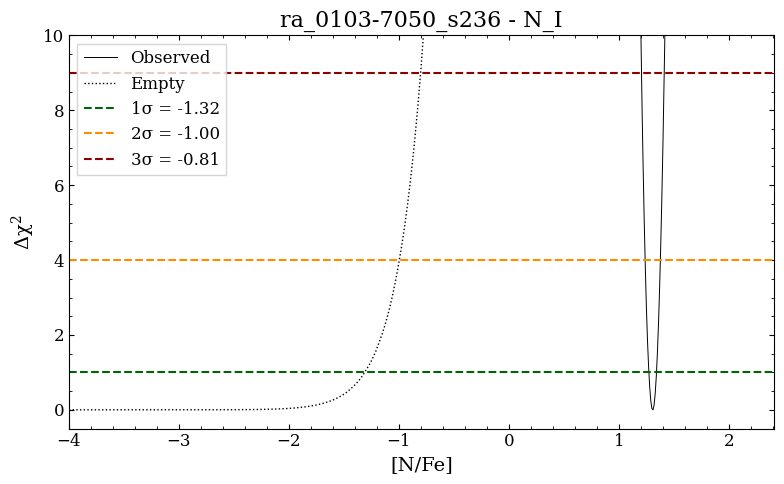

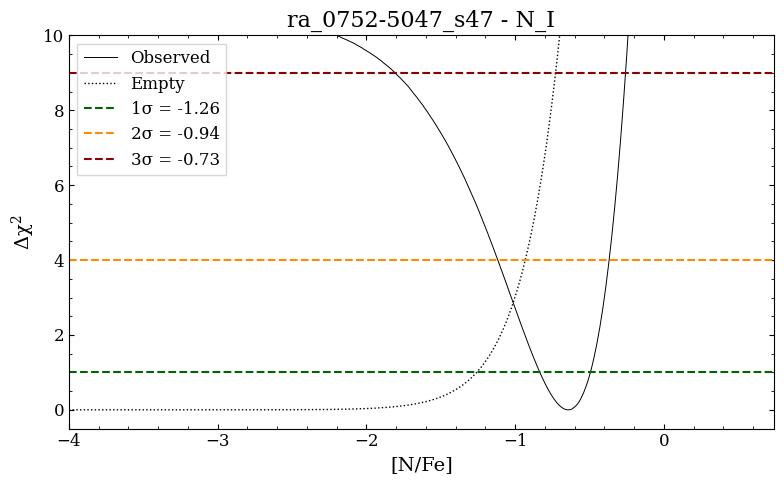

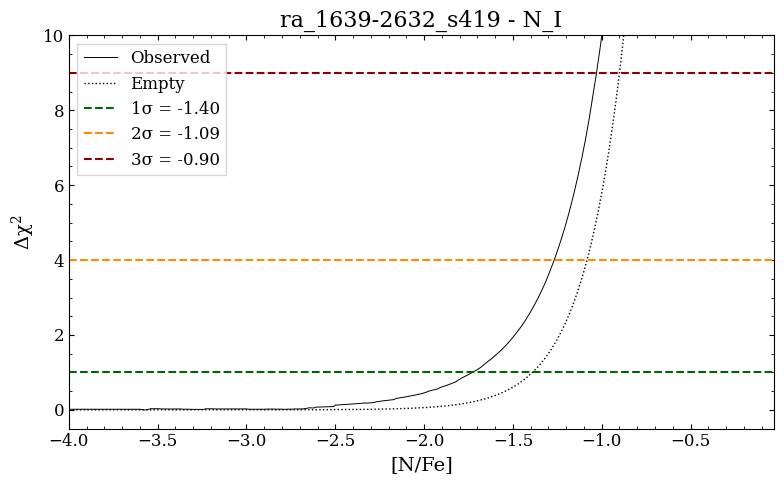

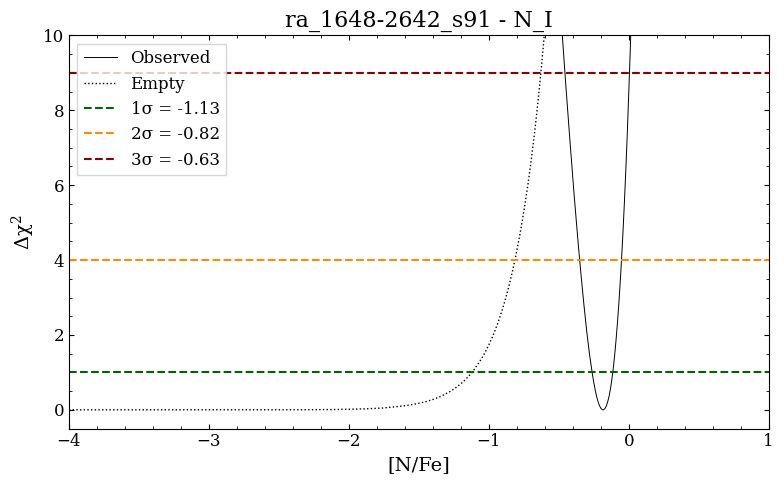

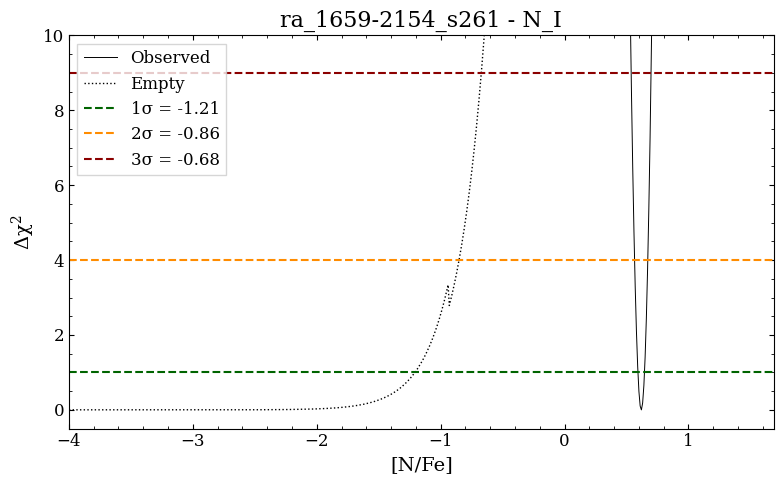

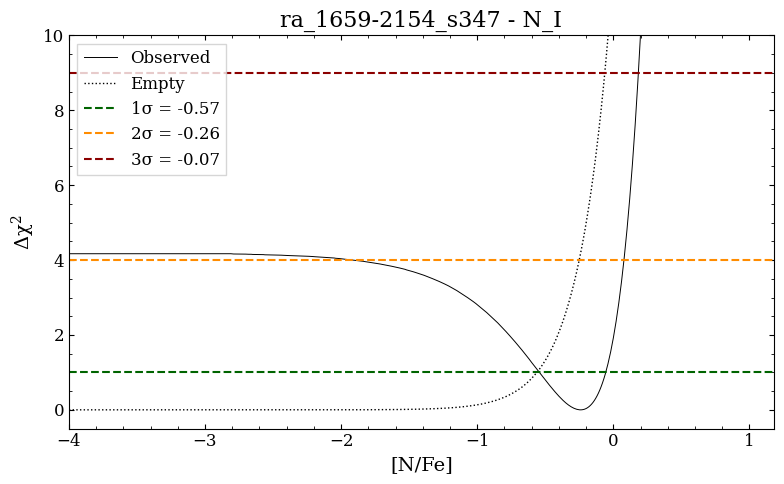

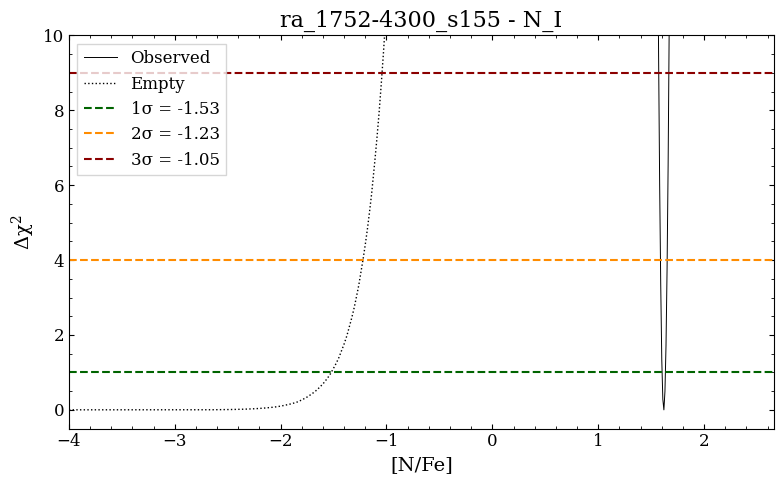

In [11]:
# Loading in the masks DataFrame
masks_nh_df = pd.read_csv('/data/misfit/benlowe/xshooter/p115/korg_data/nh_masks.csv') # '/data/misfit/benlowe/xshooter/p113/korg_data/nh_masks.csv'
masks_nh_df = masks_nh_df[masks_nh_df['star_id'].isin(N_stars)]

# Element to run chi-square on
el = 'N_I' # 'C_I'

# Path to the synthetic spectra
# synth_path = '/data/misfit/benlowe/xshooter/p113/korg_data/upper_limits_v6/'
synth_path = '/data/misfit/benlowe/xshooter/p115/korg_data/upper_limits_v2/'

# Save path for the chi-square results
# savepath = "/data/misfit/benlowe/xshooter/p113/korg_data/upper_limits_v6/"
savepath = "/data/misfit/benlowe/xshooter/p115/korg_data/upper_limits_v2/"
    
# ---CALCULATING DELTA CHI-SQUARE--- #
# Getting list of paths to each star's chisqrs.csv file
paths = [f"{savepath}{star}" for star in masks_nh_df['star_id'].values]

nh_detect_df = delta_chisqr(paths, el)

#### For CH

Running star ra_0103-7050_s236
Running star ra_0752-5047_s47
Running star ra_1639-2632_s419
Running star ra_1648-2642_s91
Running star ra_1659-2154_s261
Running star ra_1659-2154_s347
Running star ra_1752-4300_s155


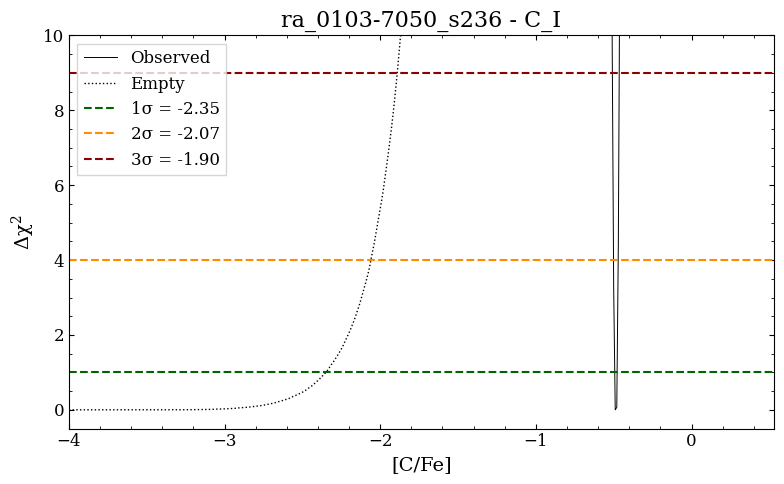

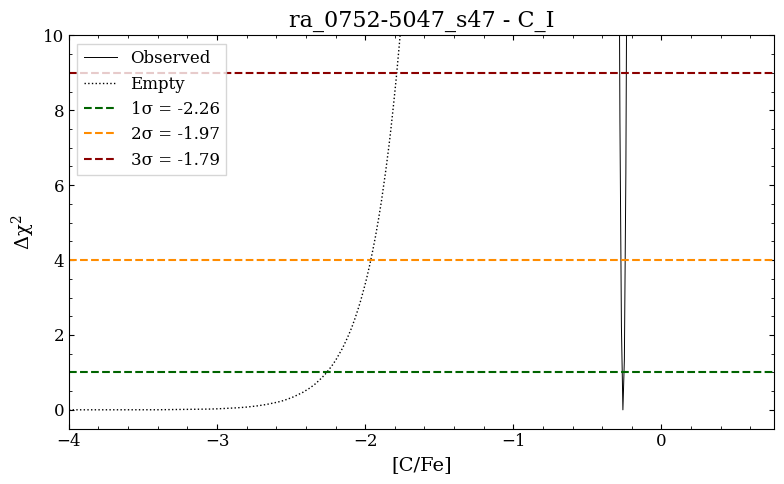

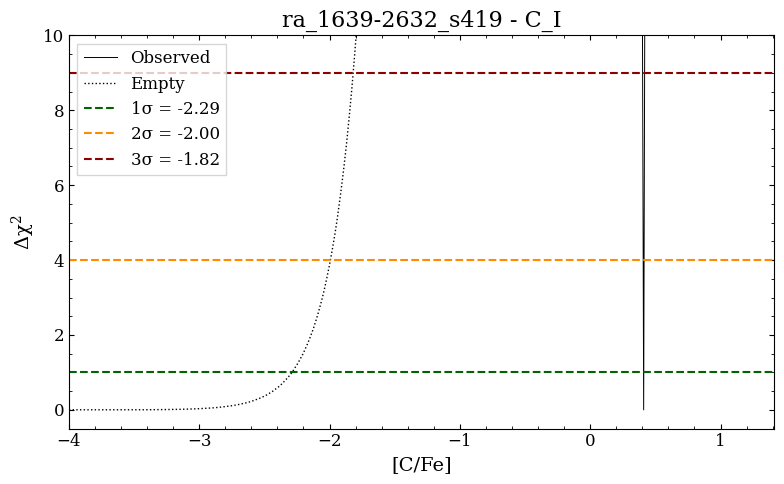

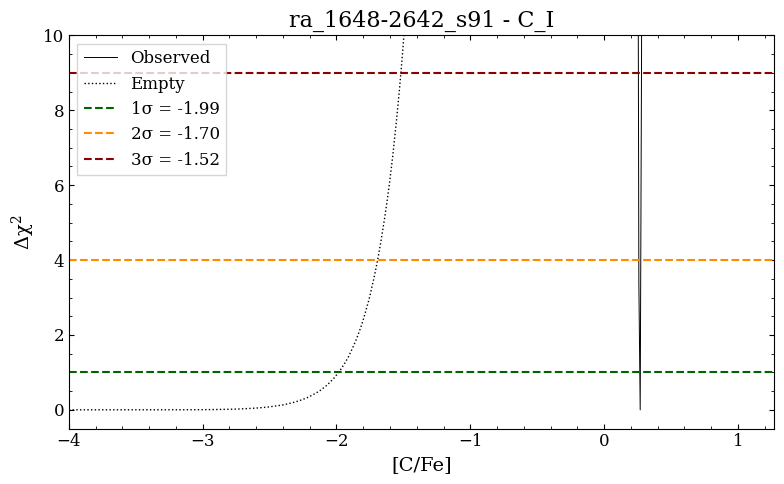

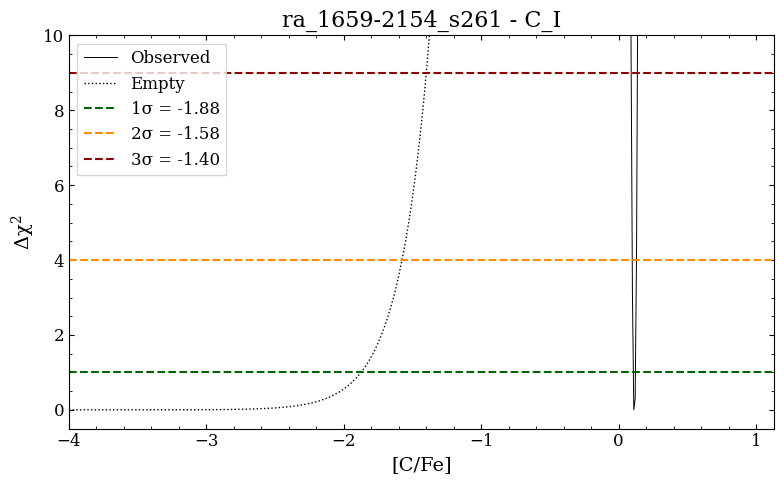

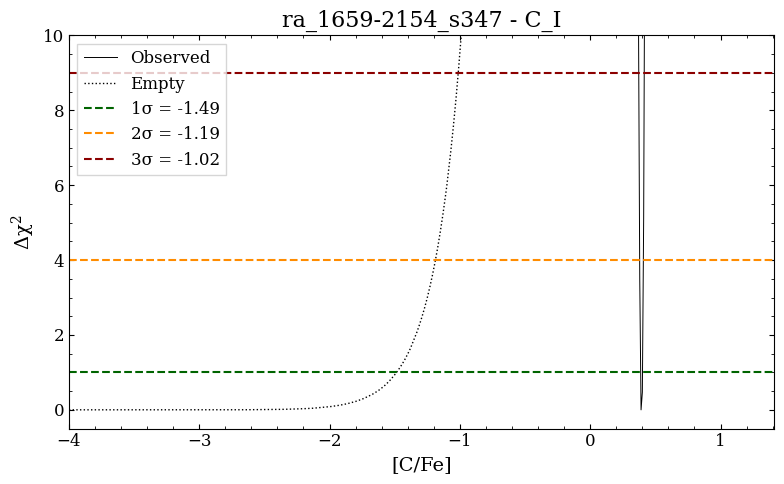

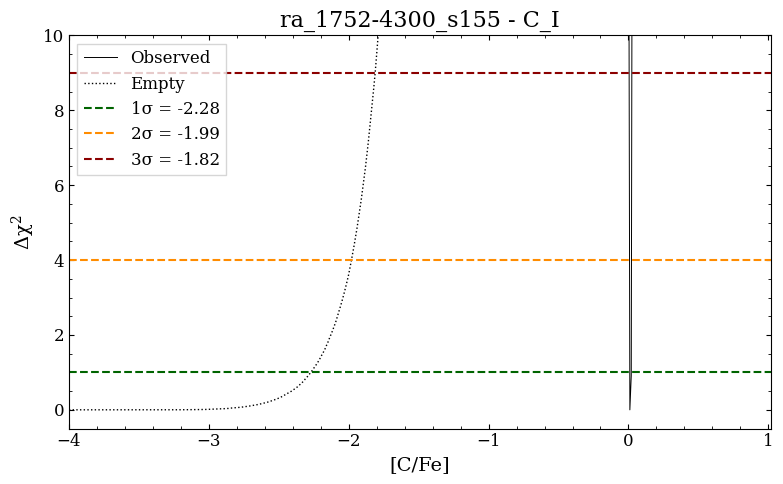

In [12]:
# Loading in the masks DataFrame
masks_ch_df = pd.read_csv('/data/misfit/benlowe/xshooter/p115/korg_data/ch_masks.csv') # '/data/misfit/benlowe/xshooter/p113/korg_data/ch_masks.csv'
masks_ch_df = masks_ch_df[masks_ch_df['star_id'].isin(N_stars)]

# Element to run chi-square on
el = 'C_I' # 'C_I'

# Path to the synthetic spectra
# synth_path = '/data/misfit/benlowe/xshooter/p113/korg_data/upper_limits_v6/'
synth_path = '/data/misfit/benlowe/xshooter/p115/korg_data/upper_limits_v2/'

# Save path for the chi-square results
# savepath = "/data/misfit/benlowe/xshooter/p113/korg_data/upper_limits_v6/"
savepath = "/data/misfit/benlowe/xshooter/p115/korg_data/upper_limits_v2/"
    
    
# ---CALCULATING DELTA CHI-SQUARE--- #
# Getting list of paths to each star's chisqrs.csv file
paths = [f"{savepath}{star}" for star in masks_ch_df['star_id'].values]

ch_detect_df = delta_chisqr(paths, el)

### Identifying detections from non-detections

To check for detections:
1. If [X/Fe] > 3sigma_detect, then this is a detection, and we adopt the fit alongside the statistical errorbars
2. If [X/Fe] < 3sigma_detect, then this is a non-detection, we adpot the 3sigma level as the upper-limit

#### For NH

In [13]:
el = "N_I"

# Loading in the abundances DataFrame
abunds_df = pd.read_csv(f'/data/misfit/benlowe/xshooter/p115/korg_data/abunds_v2/final_iter9/stellar_abunds.csv') # '/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter9/stellar_abunds.csv'

# Extracting entries for our abundance
el_df = abunds_df[['star_id', 'teff', 'logg', 'Fe_it1', f'{el}_xfe_it1', f'{el}_xfe_comberr', f'{el}_xh_it1', f'{el}_xh_comberr']]
el_df = pd.merge(nh_detect_df, el_df, on='star_id', how='left')
# display(el_df)

# Checking for detections
star_detect_all = []
for row in el_df.iterrows():
    star = row[1]['star_id']
    detect_3sig = row[1]['detect_3sigma']
    stat_error_3sig = row[1]['3sigma_errs']
    
    feh = row[1]['Fe_it1']
    teff = row[1]['teff']
    logg = row[1]['logg']
    
    fit_abund_xfe = row[1][f'{el}_xfe_it1']
    fit_abund_xfe_err = row[1][f'{el}_xfe_comberr']
    fit_abund_xh = row[1][f'{el}_xh_it1']
    fit_abund_xh_err = row[1][f'{el}_xh_comberr']
    
    
    if fit_abund_xfe >= detect_3sig:
        detection = 'Y'
        
    else:
        detection = 'N'
        
    detect_dict = {'star_id': star, 'teff': teff, 'logg': logg, 'feh': feh, 'el': el, 'detection': detection, 'min_abund_xh': detect_3sig + feh, 'min_abund_xfe': detect_3sig,
                   'bestfit_abund_xh': fit_abund_xh, 'bestfit_abund_xfe': fit_abund_xfe, 'bestfit_abund_xh_err': fit_abund_xh_err, 'bestfit_abund_xfe_err': fit_abund_xfe_err,  'stat_error_3sig': stat_error_3sig}
    star_detect_all.append(detect_dict)
        
    star_detect_df = pd.DataFrame([detect_dict])
    star_detect_df.to_csv(f"/data/misfit/benlowe/xshooter/p115/korg_data/upper_limits_v2/{star}/{el}_abunds.csv") # /data/misfit/benlowe/xshooter/p113/korg_data/upper_limits_v6/{star}/{el}_abunds.csv
        
# Converting to DataFrame 
star_detect_nh_df = pd.DataFrame(star_detect_all)

star_detect_nh_df

,star_id,teff,logg,feh,el,detection,min_abund_xh,min_abund_xfe,bestfit_abund_xh,bestfit_abund_xfe,bestfit_abund_xh_err,bestfit_abund_xfe_err,stat_error_3sig
0,ra_0103-7050_s236,4622.578329,0.994550,-2.883631,N_I,Y,-3.693631,-0.81,-1.466424,1.417207,0.131446,0.131446,0.110
1,ra_0752-5047_s47,4782.205419,2.391622,-3.051738,N_I,N,-3.781738,-0.73,-6.852978,-3.801240,1.608847,1.608847,0.780
2,ra_1639-2632_s419,5356.455582,2.873584,-2.034058,N_I,N,-2.934058,-0.90,-5.952593,-3.918535,1.957081,1.957081,NaN
3,ra_1648-2642_s91,5056.051117,2.018700,-2.808558,N_I,N,-3.438558,-0.63,-3.473433,-0.664876,0.101551,0.101551,0.235
4,ra_1659-2154_s261,5370.037228,2.921514,-2.194068,N_I,Y,-2.874068,-0.68,-1.408978,0.785090,0.086674,0.086674,0.085
5,ra_1659-2154_s347,5476.914866,3.079300,-2.829687,N_I,N,-2.899687,-0.07,-6.445486,-3.615799,0.064050,0.064050,NaN
6,ra_1752-4300_s155,4797.406576,1.413650,-2.907340,N_I,Y,-3.957340,-1.05,-1.349280,1.558061,0.107305,0.107305,0.050


#### For CH

In [14]:
el = "C_I"

# Loading in the abundances DataFrame
abunds_df = pd.read_csv(f'/data/misfit/benlowe/xshooter/p115/korg_data/abunds_v2/final_iter9/stellar_abunds.csv') # '/data/misfit/benlowe/xshooter/p113/korg_data/abunds/final_iter9/stellar_abunds.csv'

# Extracting entries for our abundance
el_df = abunds_df[['star_id', 'teff', 'logg', 'Fe_it1', f'{el}_xfe_it1', f'{el}_xfe_comberr', f'{el}_xh_it1', f'{el}_xh_comberr']]
el_df = pd.merge(ch_detect_df, el_df, on='star_id', how='left')
# display(el_df)

# Checking for detections
star_detect_all = []
for row in el_df.iterrows():
    star = row[1]['star_id']
    detect_3sig = row[1]['detect_3sigma']
    stat_error_3sig = row[1]['3sigma_errs']
    
    feh = row[1]['Fe_it1']
    teff = row[1]['teff']
    logg = row[1]['logg']
    
    fit_abund_xfe = row[1][f'{el}_xfe_it1']
    fit_abund_xfe_err = row[1][f'{el}_xfe_comberr']
    fit_abund_xh = row[1][f'{el}_xh_it1']
    fit_abund_xh_err = row[1][f'{el}_xh_comberr']
    
    
    if fit_abund_xfe >= detect_3sig:
        detection = 'Y'
        
    else:
        detection = 'N'
        
    detect_dict = {'star_id': star, 'teff': teff, 'logg': logg, 'feh': feh, 'el': el, 'detection': detection, 'min_abund_xh': detect_3sig + feh, 'min_abund_xfe': detect_3sig,
                   'bestfit_abund_xh': fit_abund_xh, 'bestfit_abund_xfe': fit_abund_xfe, 'bestfit_abund_xh_err': fit_abund_xh_err, 'bestfit_abund_xfe_err': fit_abund_xfe_err,  'stat_error_3sig': stat_error_3sig}
    star_detect_all.append(detect_dict)
        
    star_detect_df = pd.DataFrame([detect_dict])
    star_detect_df.to_csv(f"/data/misfit/benlowe/xshooter/p115/korg_data/upper_limits_v2/{star}/{el}_abunds.csv") # "/data/misfit/benlowe/xshooter/p113/korg_data/upper_limits_v6/{star}/{el}_abunds.csv"
        
# Converting to DataFrame 
star_detect_ch_df = pd.DataFrame(star_detect_all)
star_detect_ch_df

,star_id,teff,logg,feh,el,detection,min_abund_xh,min_abund_xfe,bestfit_abund_xh,bestfit_abund_xfe,bestfit_abund_xh_err,bestfit_abund_xfe_err,stat_error_3sig
0,ra_0103-7050_s236,4622.578329,0.994550,-2.883631,C_I,Y,-4.783631,-1.90,-3.541490,-0.657859,0.077155,0.077155,0.025
1,ra_0752-5047_s47,4782.205419,2.391622,-3.051738,C_I,Y,-4.841738,-1.79,-3.363455,-0.311717,0.074893,0.074893,0.030
2,ra_1639-2632_s419,5356.455582,2.873584,-2.034058,C_I,Y,-3.854058,-1.82,-1.710686,0.323371,0.071697,0.071697,0.010
3,ra_1648-2642_s91,5056.051117,2.018700,-2.808558,C_I,Y,-4.328558,-1.52,-2.621630,0.186928,0.081391,0.081391,0.015
4,ra_1659-2154_s261,5370.037228,2.921514,-2.194068,C_I,Y,-3.594068,-1.40,-2.171807,0.022261,0.073582,0.073582,0.025
5,ra_1659-2154_s347,5476.914866,3.079300,-2.829687,C_I,Y,-3.849687,-1.02,-2.398516,0.431171,0.076850,0.076850,0.025
6,ra_1752-4300_s155,4797.406576,1.413650,-2.907340,C_I,Y,-4.727340,-1.82,-2.970460,-0.063120,0.080173,0.080173,0.015


### Making [C/Fe] and [N/Fe] plots

In [26]:
def CN_spec_fit(star_df, masks_df, spec_dir, savepath, window=None):
    
    def load_spec(path, star_id, el, abund_val):
        
        # If abund_value = -0.0, then the file is at 0.0_spec.csv, not -0.0_spec.csv, so taking absolute value of 
        # abund_val to get the correct file path
        if f'{abund_val:.2f}' == '-0.00':
            abund_val = abs(abund_val)
        
        # e.g abund_val = 1.21. Spec file is at 1.21_spec.csv
        if el == 'N_I':
            try:
                spec_abund = f'{path}{star_id}/{el}/obs/line_3360.22/spectra/{abund_val:.2f}_spec.csv'
                spec_abund_df = pd.read_csv(spec_abund)
                
            # e.g abund_val = 1.20. Spec file is at 1.2_spec.csv
            except FileNotFoundError:
                spec_abund = f'{path}{star_id}/{el}/obs/line_3360.22/spectra/{abund_val:.1f}_spec.csv'
                spec_abund_df = pd.read_csv(spec_abund)
                
                
        # e.g abund_val = 1.21. Spec file is at 1.21_spec.csv
        if el == 'C_I':
            try:
                spec_abund = f'{path}{star_id}/{el}/obs/line_4300.313/spectra/{abund_val:.2f}_spec.csv'
                spec_abund_df = pd.read_csv(spec_abund)
                
            # e.g abund_val = 1.20. Spec file is at 1.2_spec.csv
            except FileNotFoundError:
                spec_abund = f'{path}{star_id}/{el}/obs/line_4300.313/spectra/{abund_val:.1f}_spec.csv'
                spec_abund_df = pd.read_csv(spec_abund)
            
        return spec_abund_df
    
    
    def bestfit_spec(path, star_id, el):
        
        # e.g abund_val = 1.21. Spec file is at 1.21_spec.csv
        if el == "C_I":
            spec_abund = f'{path}{star_id}/{el}/iter_1/fits_data/C_4300.313_fit.csv'
            spec_abund_df = pd.read_csv(spec_abund)
            
        if el == "N_I":
            spec_abund = f'{path}{star_id}/{el}/iter_1/fits_data/N_3360.22_fit.csv'
            spec_abund_df = pd.read_csv(spec_abund)
            
        return spec_abund_df
    
    
    
    # Looping over each entry in star_df
    for star in star_df.iterrows():
        
        # Extracting the stellar parameters
        star_id = star[1]['star_id']
        teff = star[1]['teff']
        logg = star[1]['logg']
        feh = star[1]['feh']
        
        # Extracting the detection information
        el = star[1]['el']
        el_ = el.split('_')[0]
        detect_flag = star[1]['detection']
        abund_val = star[1]['bestfit_abund_xfe']
        abund_err = star[1]['stat_error_3sig']
        abund_ul = star[1]['min_abund_xfe']
        
        if el == "C_I":
            
            # # Getting C abundances. 
            # # We want the uncorrected C abundances (the ones provided are corrected), so need to subtract the corrections off            
            # c_I_correct_df = pd.read_csv('/data/misfit/benlowe/xshooter/p115/C_evolve_corrections/cfe_corrections.csv')
            # c_I_val_corr = c_I_correct_df[c_I_correct_df['star_id'] == star_id]['cfe_corr'].to_numpy()[0]
                                    
            # abund_val = abund_val - c_I_val_corr
            
            # Getting the masks for CH    
            star_maskmin1 = masks_df.loc[masks_df['star_id'] == star_id, 'ch_maskmin1'].values[0]
            star_maskmax1 = masks_df.loc[masks_df['star_id'] == star_id, 'ch_maskmax1'].values[0]
            star_maskmin2 = masks_df.loc[masks_df['star_id'] == star_id, 'ch_maskmin2'].values[0]
            star_maskmax2 = masks_df.loc[masks_df['star_id'] == star_id, 'ch_maskmax2'].values[0]
            star_maskmin3 = masks_df.loc[masks_df['star_id'] == star_id, 'ch_maskmin3'].values[0]
            star_maskmax3 = masks_df.loc[masks_df['star_id'] == star_id, 'ch_maskmax3'].values[0]
            star_maskmin4 = masks_df.loc[masks_df['star_id'] == star_id, 'ch_maskmin4'].values[0]
            star_maskmax4 = masks_df.loc[masks_df['star_id'] == star_id, 'ch_maskmax4'].values[0]
            masks = [(star_maskmin1, star_maskmax1), (star_maskmin2, star_maskmax2), (star_maskmin3, star_maskmax3), (star_maskmin4, star_maskmax4)]
        
        elif el == "N_I":
            
            # Getting the masks for NH
            star_maskmin1 = masks_df.loc[masks_df['star_id'] == star_id, 'nh_maskmin'].values[0]
            star_maskmax1 = masks_df.loc[masks_df['star_id'] == star_id, 'nh_maskmax'].values[0]
            masks = [(star_maskmin1, star_maskmax1)]    

            
        
        # If abund_err is Nan, then set detection flag to N
        if np.isnan(abund_err):
            detect_flag = 'N'
    
    
        if detect_flag == 'Y':
            print(abund_val)
            # Loading in the spectra
            spec_abund_df = load_spec(path=spec_dir, star_id=star_id, el=el, abund_val=abund_val)
            spec_abund_bestfit_df = bestfit_spec(path="/data/misfit/benlowe/xshooter/p115/korg_data/abunds_v2/final_iter9/", star_id=star_id, el=el)
            spec_abund_perr_df = load_spec(path=spec_dir, star_id=star_id, el=el, abund_val=abund_val + abund_err)
            spec_abund_merr_df = load_spec(path=spec_dir, star_id=star_id, el=el, abund_val=abund_val - abund_err)
            spec_abund_empty_df = load_spec(path=spec_dir, star_id=star_id, el=el, abund_val=-3.00)
            
            # Extracting wavelength and flux
            obs_wave = np.array(ast.literal_eval(spec_abund_df['obs_wave'].to_numpy()[0]))
            obs_flux = np.array(ast.literal_eval(spec_abund_df['obs_flux'].to_numpy()[0]))
            obs_flux_err = np.array(ast.literal_eval(spec_abund_df['obs_flux_err'].to_numpy()[0]))
            bestfit_wave = np.array(ast.literal_eval(spec_abund_df['fit_wave'].to_numpy()[0]))
            bestfit_flux = np.array(ast.literal_eval(spec_abund_df['fit_flux'].to_numpy()[0]))
            # bestfit_wave = spec_abund_bestfit_df['wave'].to_numpy()
            # bestfit_flux = spec_abund_bestfit_df['best_fit'].to_numpy()
            pfit_wave = np.array(ast.literal_eval(spec_abund_perr_df['fit_wave'].to_numpy()[0]))
            pfit_flux = np.array(ast.literal_eval(spec_abund_perr_df['fit_flux'].to_numpy()[0]))
            mfit_wave = np.array(ast.literal_eval(spec_abund_merr_df['fit_wave'].to_numpy()[0]))
            mfit_flux = np.array(ast.literal_eval(spec_abund_merr_df['fit_flux'].to_numpy()[0]))
            emptyfit_wave = np.array(ast.literal_eval(spec_abund_empty_df['fit_wave'].to_numpy()[0]))
            emptyfit_flux = np.array(ast.literal_eval(spec_abund_empty_df['fit_flux'].to_numpy()[0]))
            
            if window is not None:
                obs_wavelim = np.where((obs_wave >= window[0]) & (obs_wave <= window[1]))
                obs_wave = obs_wave[obs_wavelim]
                obs_flux = obs_flux[obs_wavelim]
                obs_flux_err = obs_flux_err[obs_wavelim]
                
                bestfit_wavelim = np.where((bestfit_wave >= window[0]) & (bestfit_wave <= window[1]))
                bestfit_wave = bestfit_wave[bestfit_wavelim]
                bestfit_flux = bestfit_flux[bestfit_wavelim]
                
                pfit_wavelim = np.where((pfit_wave >= window[0]) & (pfit_wave <= window[1]))                
                pfit_wave = pfit_wave[obs_wavelim]
                pfit_flux = pfit_flux[obs_wavelim]

                mfit_wavelim = np.where((mfit_wave >= window[0]) & (mfit_wave <= window[1]))                                
                mfit_wave = mfit_wave[mfit_wavelim]
                mfit_flux = mfit_flux[mfit_wavelim]
                
                emptyfit_wavelim = np.where((emptyfit_wave >= window[0]) & (emptyfit_wave <= window[1]))
                emptyfit_wave = emptyfit_wave[emptyfit_wavelim]
                emptyfit_flux = emptyfit_flux[emptyfit_wavelim]
            
            
            plt.figure(figsize=(8, 6))
            plt.plot(obs_wave, obs_flux, linewidth=0.65, color='black', label='{0}\n[{1}, {2:.2f}, {3:.2f}]'.format(star_id, int(round(teff, ndigits=-1)), logg, feh))
            plt.errorbar(obs_wave, obs_flux, yerr=obs_flux_err, fmt='o', markersize=2, color='grey', alpha=0.5)
            plt.plot(bestfit_wave, bestfit_flux, linewidth=2, color='darkred', label='[{0}/Fe] = {1:.2f} ± {2:.2f}'.format(el_, abund_val, abund_err))
            plt.plot(pfit_wave, pfit_flux, linewidth=0.8, color='darkred')
            plt.plot(mfit_wave, mfit_flux, linewidth=0.8, color='darkred')
            # plt.plot(emptyfit_wave, emptyfit_flux, linewidth=1.5, color='black', linestyle='--', label='[{0}/Fe] = -3.00'.format(el_))
            plt.fill_between(obs_wave, pfit_flux, mfit_flux, color='red', alpha=0.3)
            
            ymin, ymax = plt.gca().get_ylim()        
            for start, end in masks:
                fill_range = (obs_wave >= start) & (obs_wave <= end)
                plt.fill_between(obs_wave[fill_range], y1=ymin, y2=ymax, color="black", alpha=0.1)


            plt.xlabel('Wavelength (Å)')
            plt.ylabel('Normalised Flux')
            plt.legend(fancybox=False, loc='lower left')
            plt.tight_layout()
            plt.savefig(savepath + star_id + "_plot_v3.png", dpi=300, bbox_inches='tight')
            plt.savefig(savepath + star_id + "_plot_v3.pdf", dpi=300, bbox_inches='tight')



        if detect_flag == 'N':
            
            # Loading in the spectra
            spec_abund_ul_df = load_spec(path=spec_dir, star_id=star_id, el=el, abund_val=abund_ul)
            spec_abund_empty_df = load_spec(path=spec_dir, star_id=star_id, el=el, abund_val=-3.00)
            # spec_abund_ref_df = load_spec(path=spec_dir, star_id=star_id, el=el, abund_val=0.50)
            spec_abund_ref_df = load_spec(path=spec_dir, star_id=star_id, el=el, abund_val=0.0)
            
            # Extracting wavelength and flux
            obs_wave = np.array(ast.literal_eval(spec_abund_ul_df['obs_wave'].to_numpy()[0]))
            obs_flux = np.array(ast.literal_eval(spec_abund_ul_df['obs_flux'].to_numpy()[0]))
            obs_flux_err = np.array(ast.literal_eval(spec_abund_ul_df['obs_flux_err'].to_numpy()[0]))
            ul_wave = np.array(ast.literal_eval(spec_abund_ul_df['fit_wave'].to_numpy()[0]))
            ul_flux = np.array(ast.literal_eval(spec_abund_ul_df['fit_flux'].to_numpy()[0]))
            ref_wave = np.array(ast.literal_eval(spec_abund_ref_df['fit_wave'].to_numpy()[0]))
            ref_flux = np.array(ast.literal_eval(spec_abund_ref_df['fit_flux'].to_numpy()[0]))
            emptyfit_wave = np.array(ast.literal_eval(spec_abund_empty_df['fit_wave'].to_numpy()[0]))
            emptyfit_flux = np.array(ast.literal_eval(spec_abund_empty_df['fit_flux'].to_numpy()[0]))
            
            if window is not None:
                obs_wavelim = np.where((obs_wave >= window[0]) & (obs_wave <= window[1]))
                obs_wave = obs_wave[obs_wavelim]
                obs_flux = obs_flux[obs_wavelim]
                obs_flux_err = obs_flux_err[obs_wavelim]
                
                ul_wavelim = np.where((ul_wave >= window[0]) & (ul_wave <= window[1]))
                ul_wave = ul_wave[ul_wavelim]
                ul_flux = ul_flux[ul_wavelim]
                
                ref_wavelim = np.where((ref_wave >= window[0]) & (ref_wave <= window[1]))
                ref_wave = ref_wave[ref_wavelim]
                ref_flux = ref_flux[ref_wavelim]
                
                emptyfit_wavelim = np.where((emptyfit_wave >= window[0]) & (emptyfit_wave <= window[1]))
                emptyfit_wave = emptyfit_wave[emptyfit_wavelim]
                emptyfit_flux = emptyfit_flux[emptyfit_wavelim]
            
            
            plt.figure(figsize=(8, 6))
            plt.plot(obs_wave, obs_flux, linewidth=0.65, color='black', label='{0}\n[{1}, {2:.2f}, {3:.2f}]'.format(star_id, int(round(teff, ndigits=-1)), logg, feh), zorder=10)
            plt.errorbar(obs_wave, obs_flux, yerr=obs_flux_err, fmt='o', markersize=2, color='grey', alpha=0.5)
            plt.plot(ul_wave, ul_flux, linewidth=2, color='darkblue', label='[{0}/Fe] < {1:.2f}'.format(el_, abund_ul), zorder=5)
            plt.plot(ref_wave, ref_flux, linewidth=2, color='cornflowerblue', linestyle='-.', zorder=0, label=f"[{el_}/Fe] = 0.00") # label='[{0}/Fe]_ref = 0.50'.format(el_)
            plt.plot(emptyfit_wave, emptyfit_flux, linewidth=2, color='black', linestyle='--', label="Empty spectum") # label='[{0}/Fe] = -3.00'.format(el_)
            # plt.fill_between(obs_wave, pfit_flux, mfit_flux, color='red', alpha=0.3)
            
            ymin, ymax = plt.gca().get_ylim()        
            for start, end in masks:
                fill_range = (obs_wave >= start) & (obs_wave <= end)
                plt.fill_between(obs_wave[fill_range], y1=ymin, y2=ymax, color="black", alpha=0.1)

            plt.xlabel('Wavelength (Å)')
            plt.ylabel('Normalised Flux')
            plt.legend(fancybox=False, loc='lower left')
            plt.tight_layout()
            plt.savefig(savepath + star_id + "_plot_v3.png", dpi=300, bbox_inches='tight')
            plt.savefig(savepath + star_id + "_plot_v3.pdf", dpi=300, bbox_inches='tight')

-0.6578591249997117
-0.3117169683537599
0.3233713233287476
0.186927889199711
0.0222611271844979
0.4311706207705184
-0.0631200565924339


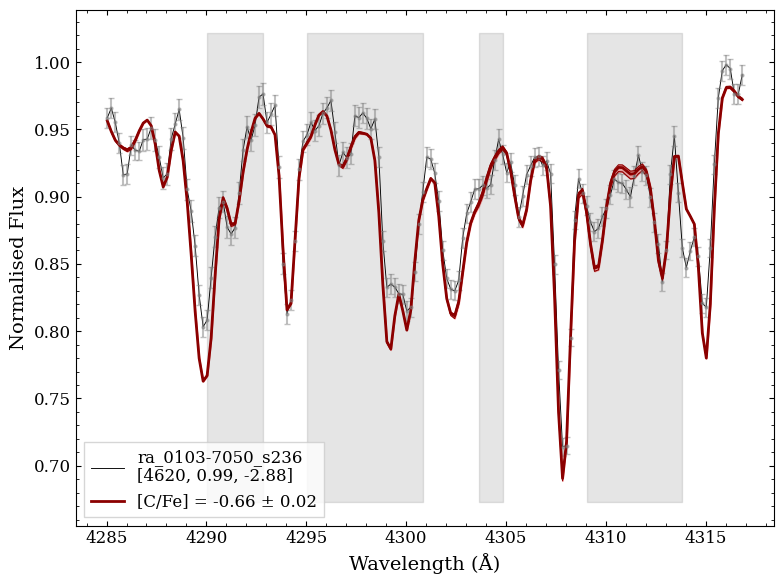

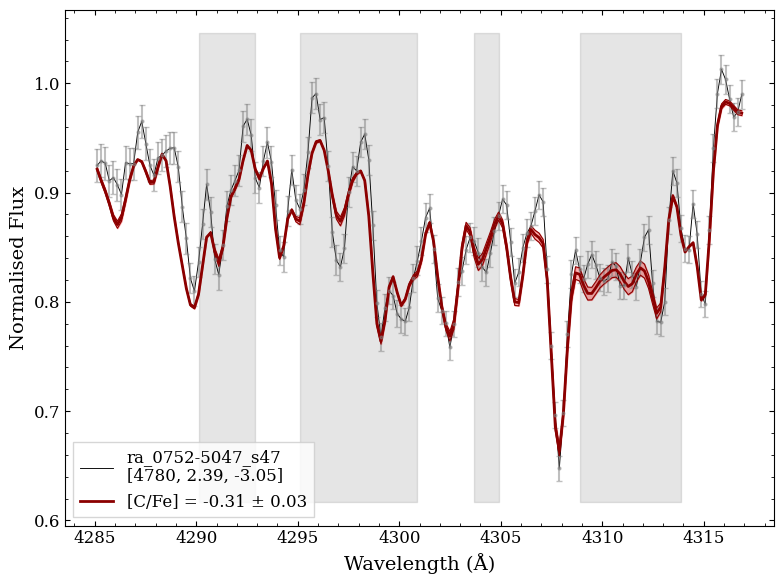

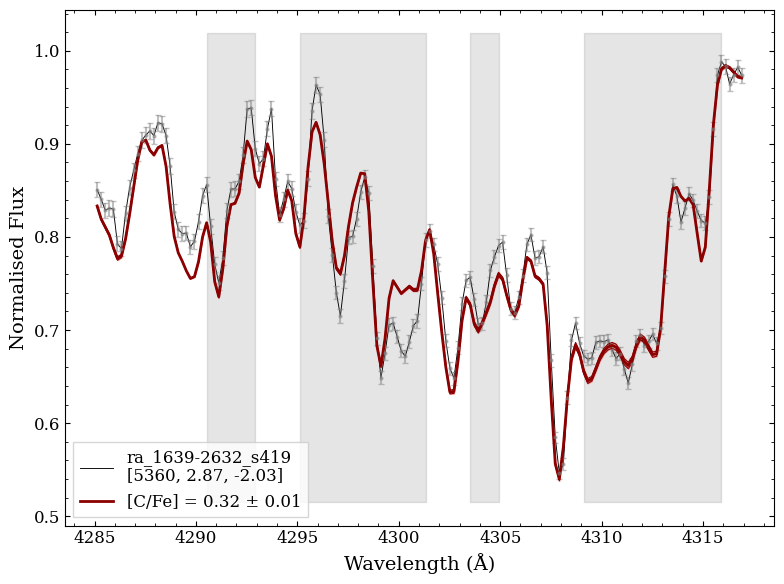

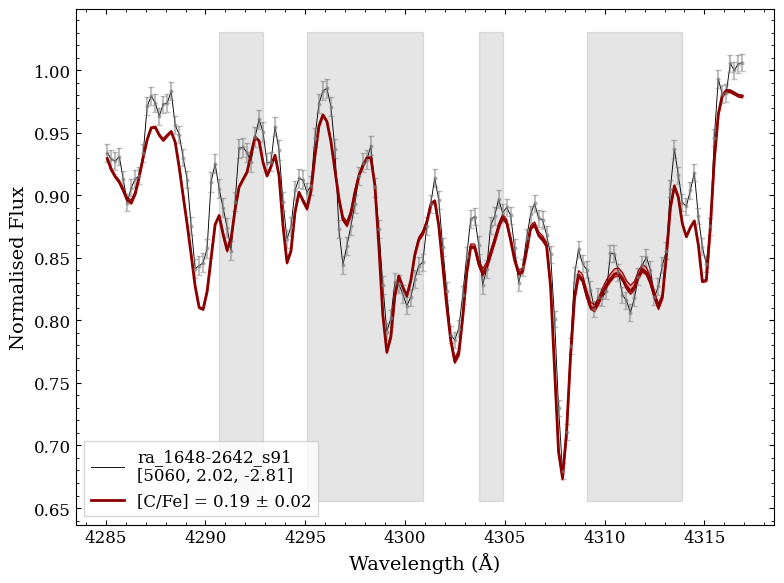

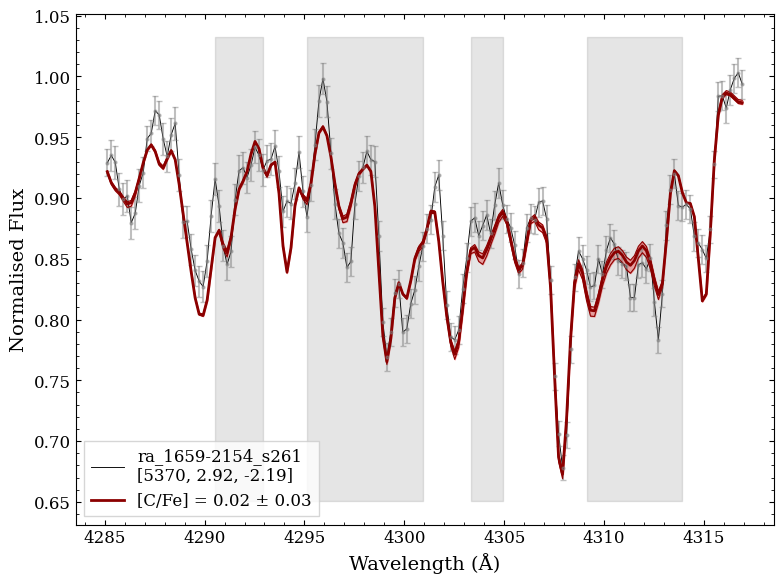

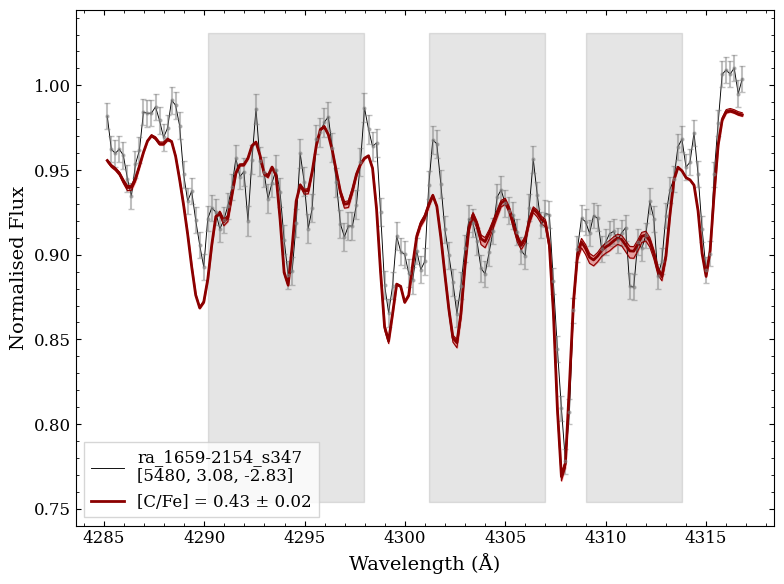

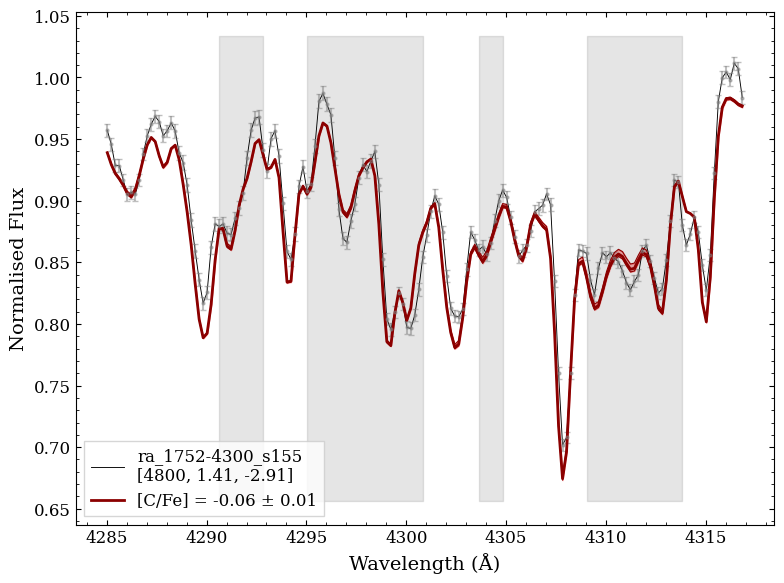

In [17]:
windows_ch = [4285, 4317]
savepath_ch = '/data/misfit/benlowe/xshooter/p115/results/star_abunds/ch_fits/'

CN_spec_fit(star_df=star_detect_ch_df, 
            masks_df=masks_ch_df, 
            spec_dir="/data/misfit/benlowe/xshooter/p115/korg_data/synths_v2/", 
            savepath=savepath_ch,
            window=windows_ch)

In [27]:
# Making table for paper

dict_list = []
for star in star_detect_ch_df.iterrows():
    
    detect = star[1]['detection']
    
    # If detection, then take fitted value with fitted error
    if detect == 'Y' and not np.isnan(star[1]['stat_error_3sig']):
        c_val = f"${star[1]['bestfit_abund_xfe']:.2f} \pm {star[1]['bestfit_abund_xfe_err']:.2f}$"
        stat_err = f"${star[1]['stat_error_3sig']:.2f}$"
        
    # If non-detection, then take upper-limit. Stat error will be left blank
    else:
        c_val = f"$<{star[1]['min_abund_xfe']:.2f}$"
        stat_err = ''

    ch_dict = {'Star': star[1]['star_id'], '\XFe{C}': c_val, '$\sigma_{\rm stat}$': stat_err}
    dict_list.append(ch_dict)
    
cn_final_tab = pd.DataFrame(dict_list)
cn_final_tab.sort_values(by='Star', inplace=True)

print(cn_final_tab.to_latex(index=False))


\begin{tabular}{lll}
\toprule
m stat}$ \\{C} & $\sigma_{
\midrule
ra_0103-7050_s163 & $<0.12$ &  \\
ra_0834-5220_s316 & $<0.27$ &  \\
ra_1604-2712_s24 & $0.06 \pm 0.08$ & $0.02$ \\
ra_1604-2712_s292 & $<0.53$ &  \\
ra_1624-2150_s278 & $<1.09$ &  \\
ra_1633-2814_s130 & $0.27 \pm 0.08$ & $0.06$ \\
ra_1633-2814_s284 & $0.66 \pm 0.08$ & $0.12$ \\
ra_1648-0653_s38 & $0.39 \pm 0.08$ & $0.16$ \\
ra_1656-1433_s143 & $0.42 \pm 1.39$ & $0.02$ \\
ra_1658-2454_s22 & $-0.37 \pm 0.08$ & $0.02$ \\
ra_1659-2154_s114 & $0.11 \pm 0.09$ & $0.06$ \\
ra_1709-2130_s102 & $0.07 \pm 0.08$ & $0.03$ \\
ra_1752-4300_s214 & $0.85 \pm 0.08$ & $0.02$ \\
ra_1752-4300_s269 & $0.32 \pm 0.09$ & $0.02$ \\
ra_1752-4300_s6 & $0.58 \pm 0.76$ & $0.02$ \\
ra_1853-3255_s45 & $0.18 \pm 0.08$ & $0.01$ \\
\bottomrule
\end{tabular}



1.4172068880263748
0.7850902912372568
1.5580607260841048


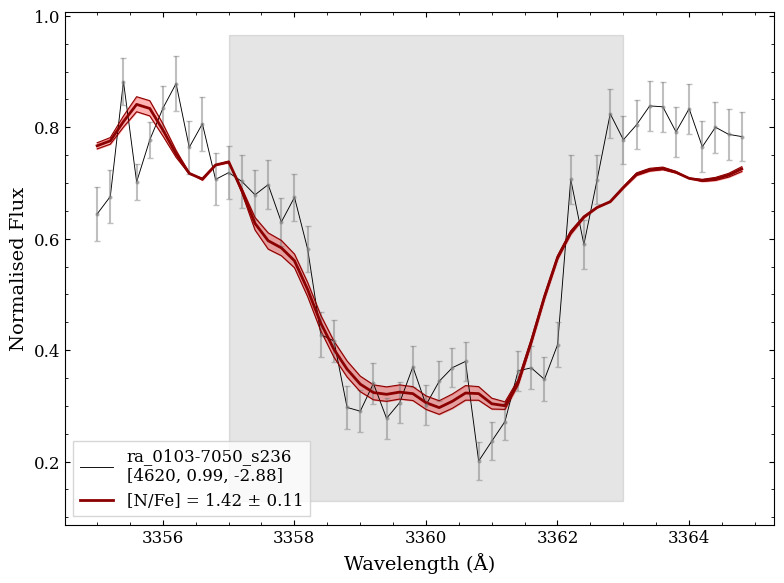

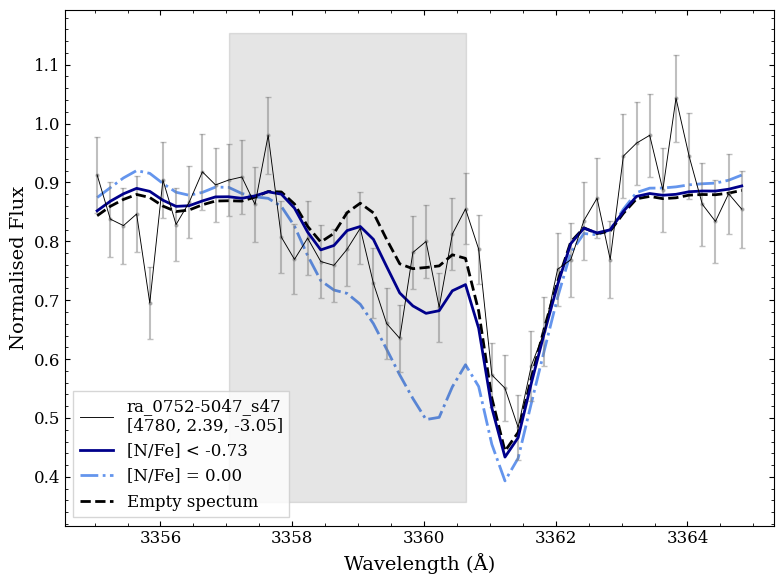

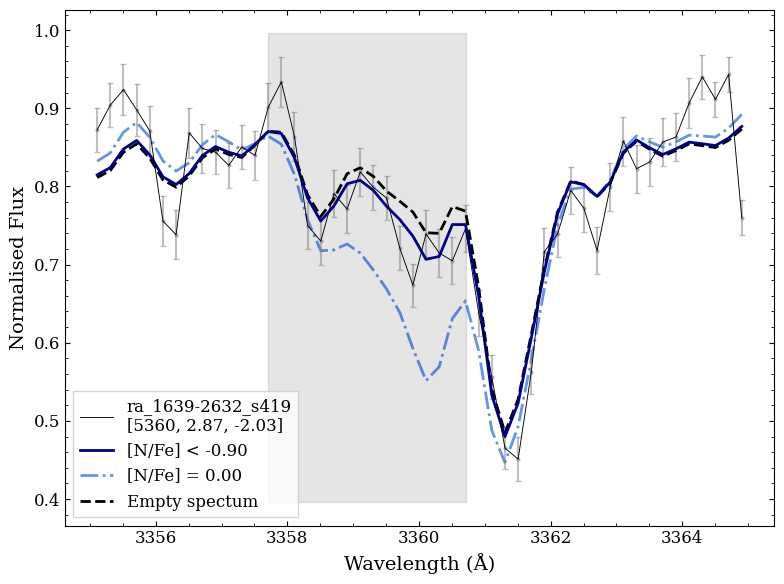

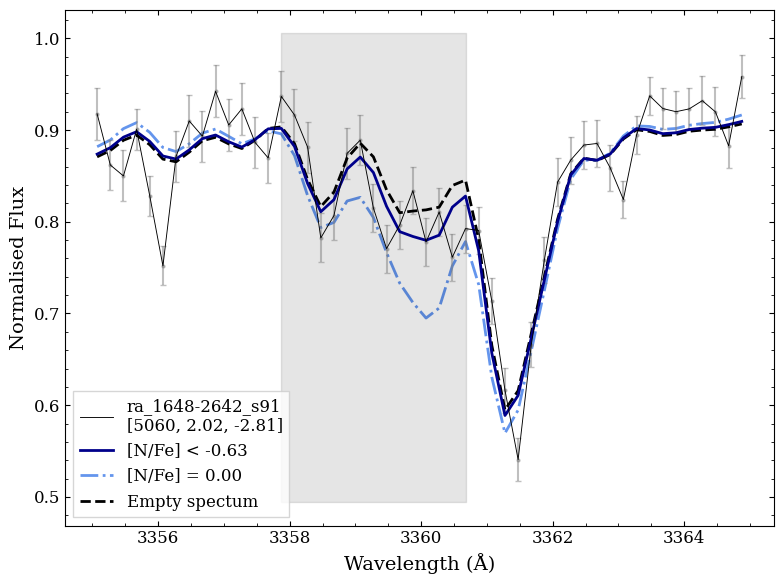

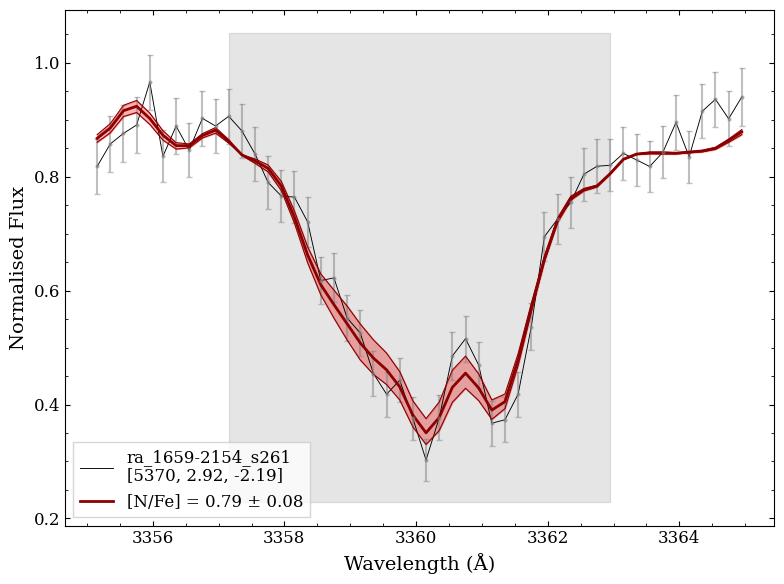

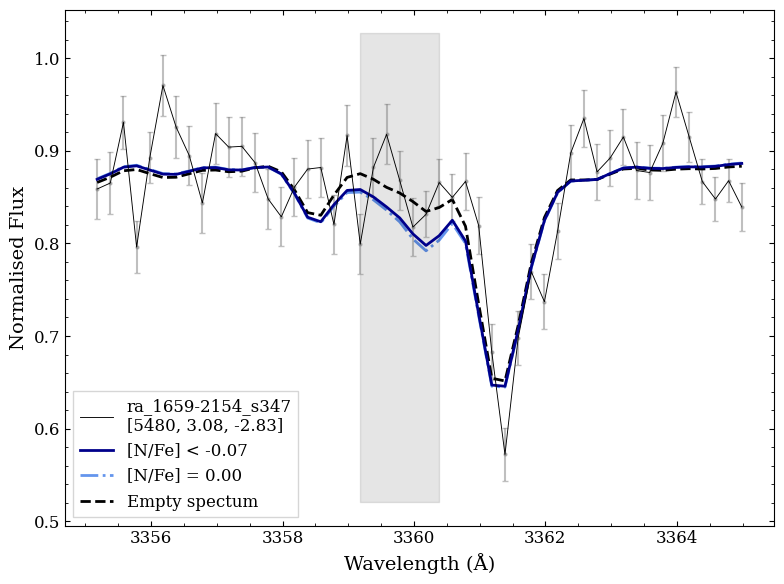

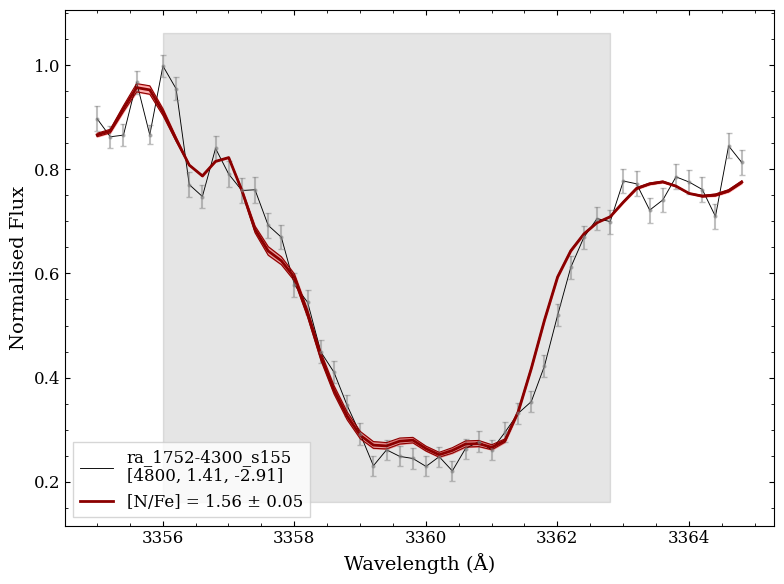

In [27]:
windows_nh = [3355, 3365]
savepath_nh = '/data/misfit/benlowe/xshooter/p115/results/star_abunds/nh_fits/'


CN_spec_fit(star_df=star_detect_nh_df, 
            masks_df=masks_nh_df, 
            spec_dir="/data/misfit/benlowe/xshooter/p115/korg_data/synths_v2/", 
            savepath=savepath_nh,
            window=windows_nh)

In [ ]:
stars = stars_data['star_id'].to_numpy()
params_rounded = pd.read_csv('/data/misfit/benlowe/xshooter/p113/stellar_params/star_params_rd.csv')

for star in stars:

    # Getting the entries for the star
    star_data = stars_upperlimits[stars_upperlimits['star_id'] == star]
    star_params = stars_data[stars_data['star_id'] == star]
    
    # Stellar parameters
    star_teff = params_rounded[params_rounded['star_id'] == star]['teff'].to_numpy()[0]
    star_logg = params_rounded[params_rounded['star_id'] == star]['logg'].to_numpy()[0]
    star_feh = params_rounded[params_rounded['star_id'] == star]['feh'].to_numpy()[0]
    star_snr = star_params['snr_uvb'].to_numpy()[0]
    params = {'star_id': star, 'teff': star_teff, 'logg': star_logg, 'feh': star_feh, 'snr': star_snr}

    # Getting C abundances. 
    # We want the uncorrected C abundances (the ones provided are corrected), so need to subtract the corrections off
    c_I_df = star_data[star_data['el'] == 'C_I']
    c_I_detect = c_I_df['detection'].to_numpy()[0]
    c_I_val = c_I_df['bestfit_abund_xfe'].to_numpy()[0]
    c_I_err = c_I_df['bestfit_abund_comberr_xfe'].to_numpy()[0]
    c_I_ul = c_I_df['upper_limit_xfe'].to_numpy()[0]
    
    c_I_correct_df = pd.read_csv('/data/misfit/benlowe/xshooter/p113/C_evolve_corrections/cfe_corrections.csv')
    c_I_val_corr = c_I_correct_df[c_I_correct_df['star_id'] == star]['cfe_corr'].to_numpy()[0]
    
    if star == 'ra_1656-1433_s143':
        c_I_err = c_I_abunds[c_I_abunds['star_id'] == 'ra_1656-1433_s143']['bestfit_abund_tefferr_xfe'].to_numpy()[0]
        
    if star == 'ra_1752-4300_s6':
        c_I_err = c_I_abunds[c_I_abunds['star_id'] == 'ra_1752-4300_s6']['bestfit_abund_tefferr_xfe'].to_numpy()[0]
                
                
    c_I_val = c_I_val - c_I_val_corr
    
    # c_I_abunds.loc[c_I_abunds['star_id'] == 'ra_1656-1433_s143', 'bestfit_abund_comberr_xfe'] = c_I_abunds[c_I_abunds['star_id'] == 'ra_1656-1433_s143']['bestfit_abund_tefferr_xfe']
    # c_I_abunds.loc[c_I_abunds['star_id'] == 'ra_1752-4300_s6', 'bestfit_abund_comberr_xfe'] = c_I_abunds[c_I_abunds['star_id'] == 'ra_1752-4300_s6']['bestfit_abund_tefferr_xfe']

    
    
    # if star == 'ra_1656-1433_s143':
    #     c_I_val = 0.358195 - c_I_val_corr
    #     c_I_err = abs(c_I_val - (0.588063 - c_I_val_corr))
    # else:
    #     c_I_val = c_I_val - c_I_val_corr
    
    # Getting N abundances
    n_I_abunds = star_data[star_data['el'] == 'N_I']
    n_I_detect = n_I_abunds['detection'].to_numpy()[0]
    n_I_val = n_I_abunds['bestfit_abund_xfe'].to_numpy()[0]
    n_I_err = n_I_abunds['bestfit_abund_comberr_xfe'].to_numpy()[0]  
    n_I_ul = n_I_abunds['upper_limit_xfe'].to_numpy()[0]
    
    # if n_I_ul < -2.00:
    #     n_I_ul = -2.00
    
    # Directory to spectral data
    spec_c_dir = f'/data/misfit/benlowe/xshooter/p113/korg_data/synths/{star}/C_I/obs/line_4300.313/spectra/'
    spec_n_dir = f'/data/misfit/benlowe/xshooter/p113/korg_data/synths/{star}/N_I/obs/line_3360.22/spectra/'
    
    # Save path
    cfe_savepath = '/data/misfit/benlowe/xshooter/p113/results/ch_nh_fits/cfe_plots/'
    nfe_savepath = '/data/misfit/benlowe/xshooter/p113/results/ch_nh_fits/nfe_plots/'

    plt.figure(figsize=(8, 6))
    CN_spec_fit(detect_flag=c_I_detect, spec_dir=spec_c_dir, element='C', abund_val=c_I_val, abund_err=c_I_err, 
                abund_ul=c_I_ul, star_params=params, wavelim=[4260, 4330], savepath=cfe_savepath)
    
    plt.figure(figsize=(8, 6))
    CN_spec_fit(detect_flag=n_I_detect, spec_dir=spec_n_dir, element='N', abund_val=n_I_val, abund_err=n_I_err, 
                abund_ul=n_I_ul, star_params=params, wavelim=[3350, 3370], savepath=nfe_savepath)
    
    # [3350, 3370]
            

# Calculating log likelihoods

Determining log likelihoods

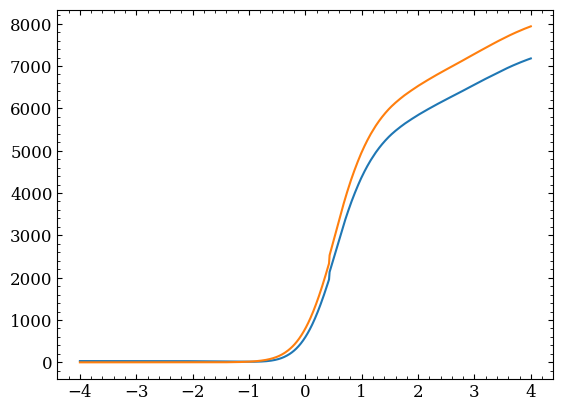

In [ ]:
# Loading in chisquares
chisqr = pd.read_csv('/data/misfit/benlowe/xshooter/p113/korg_data/upper_limits_v4/ra_1658-2454_s22/N_I/chisqrs.csv')
chisqr.sort_values('xfe', inplace=True)

# Loading in flux errors, then masking out atomic lines
obs_wave = pd.read_csv('/data/misfit/benlowe/xshooter/p113/korg_data/upper_limits_v6/ra_1658-2454_s22/N_I/synth_specs/-0.1_spec.csv')['obs_wave']
obs_flux_errs = pd.read_csv('/data/misfit/benlowe/xshooter/p113/korg_data/upper_limits_v6/ra_1658-2454_s22/N_I/synth_specs/-0.1_spec.csv')['obs_flux_err']

masks = [(3356.5, 3359.2), (3362.1, 3363.5)]
mask_obs = np.ones_like(obs_wave, dtype=bool)
for start, end in masks:
    mask_obs &= ~((obs_wave >= start) & (obs_wave <= end))

obs_flux_errs_masked = obs_flux_errs[mask_obs]

plt.figure()
plt.plot(chisqr['xfe'], chisqr['chisq_obs'], label='Observed')
plt.plot(chisqr['xfe'], chisqr['chisq_empty'], label='Empty')

In [10]:
def closest_val(array, x):
    """Within an array, finds the value closest to x.

    Parameters
    ----------
    array : ndarray
        Array of values.
    x : float
        Desired value to find closest entry to in array.

    Returns
    -------
    min_index : int
        Index of closest value to x in array.
    """
    arr_diff = np.abs(array - x) # Take x, then subtract that from every entry in the array
    min_index = np.argmin(arr_diff) # Finding the index of the smallest difference
    return min_index

def lnL_obs(npix, flux_err, chisq_red):
    """Computes the log likelihood of a given observed dataset.

    Parameters
    ----------
    npix : int
        Number of pixels within the given wavelength region.
    flux_err : ndarray
        Array of observed flux errors.
    chisq_red : ndarray
        Array of chi-squared values.

    Returns
    -------
    ndarray
        Array of the observed log likelihoods for the dataset.
    """
    return -1/2 * (chisq_red * npix) + 1/2 * np.sum(np.log(np.sqrt(2 * np.pi) * flux_err))

def lnL_model(npix, flux_err, chisq_red):
    """Computes the log likelihood of a given model dataset.

    Parameters
    ----------
    npix : int
        Number of pixels within the given wavelength region.
    flux_err : ndarray
        Array of observed flux errors.
    chisq_red : ndarray
        Array of model chi-squared values.

    Returns
    -------
    ndarray
        Array of the observed log likelihoods for the dataset.
    """
    return -1/2 * (chisq_red * npix) + 1/2 * np.sum(np.log(np.sqrt(2 * np.pi) * flux_err))

def p_calc(lnL, cfe_arr):
    """Performs the cumlative integral on a given log likelihood and [C/Fe] values.

    Parameters
    ----------
    lnL : ndarray
        Array of log likelihoods of dataset
    cfe_arr : ndarray
        Array of [C/Fe] values.
        
    Returns
    -------
    p_norm : ndarray
        Array of normalized P values
    """
    
    # Performing the cumulative integral
    p = scipy.integrate.cumulative_trapezoid(y=np.exp(lnL - np.max(lnL)), x=10**cfe_arr, initial=0) # '- np.max(thing1)' to make numbers sensible.
    
    # Normalizing
    p_norm = p/np.max(p)
    
    return p_norm


For observed

In [11]:
# Computing log likelihood for the observed dataset
star_lnL = lnL_obs(npix=len(obs_flux_errs_masked), flux_err=obs_flux_errs_masked, chisq_red=chisqr['chisq_obs'])

# Calculating the cumulative integral for the observed log likelihood
star_pnorm = p_calc(lnL=star_lnL, cfe_arr=chisqr['xfe'])

# Determining P_norm between P(x=1) and P(x=-1)
pnorm_m1 = scipy.stats.norm.cdf(x=-1)
pnorm_0 = scipy.stats.norm.cdf(x=0)
pnorm_p1 = scipy.stats.norm.cdf(x=1)

# Using these P_norm values to find corresponding [C/Fe] values
index_pnorm_m1 = closest_val(array=star_pnorm, x=pnorm_m1)
star_nfe_m1 = chisqr['xfe'][index_pnorm_m1]

index_pnorm_0 = closest_val(array=star_pnorm, x=pnorm_0)
star_nfe_p0 = chisqr['xfe'][index_pnorm_0]

index_pnorm_p1 = closest_val(array=star_pnorm, x=pnorm_p1)
star_nfe_p1 = chisqr['xfe'][index_pnorm_p1]

# Finding correspondiong [C/Fe] 2sigma and 1 sigma errors
star_nfe_2sig_err = star_nfe_p1 - star_nfe_m1
star_nfe_1sig_err = star_nfe_2sig_err/2


For null hypothesis

In [12]:
# Computing log likelihood of model dataset
synth_lnL = lnL_model(npix=len(obs_flux_errs_masked), flux_err=obs_flux_errs_masked, chisq_red=chisqr['chisq_empty'])

# Calculating the cumulative integral
synth_pnorm_nfemin = p_calc(lnL=synth_lnL, cfe_arr=chisqr['xfe'])

# Determining detection limit at P(x=2)
pnorm_p2 = scipy.stats.norm.cdf(x=2)

index_synth_pnorm_p2 = closest_val(array=synth_pnorm_nfemin, x=pnorm_p2)
star_nfe_p2 = chisqr['xfe'][index_synth_pnorm_p2] # 2sigma detection limit


In [14]:
# If 2 sigma detection limit greater than observed, then flag as 'no'. Otherwise detections are 'yes'
if star_nfe_p2 >= star_nfe_p0:
    detect_flag = 'no'
    
if star_nfe_p2 < star_nfe_p0:
    detect_flag = 'yes'
    
print(detect_flag)
print(star_nfe_p2)

no
-2.03


In [93]:
print(len(obs_flux_errs))

52


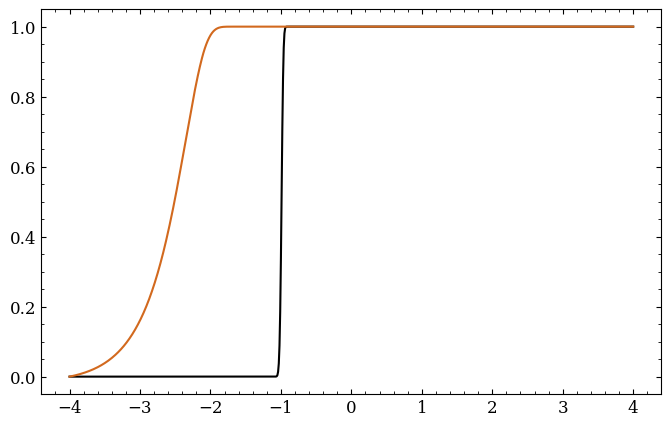

In [13]:
plt.figure(figsize=(8,5))
plt.plot(chisqr['xfe'], star_pnorm, label='Observed', color='black')
plt.plot(chisqr['xfe'], synth_pnorm_nfemin, label='Empty', color='chocolate')
# plt.axvline(star_nfe_p0, color='grey', linestyle='--', label='Median')
# plt.axvline(star_nfe_m1, color='blue', linestyle=':', label='-1σ')
# plt.axvline(star_nfe_p1, color='red', linestyle=':', label='+1σ')